# **Malaria Detection Using Deep Learning**

## **Problem Definition**

### **Context**

Malaria is a life-threatening infectious disease caused by Plasmodium parasites, transmitted to humans through the bites of infected female Anopheles mosquitoes. Once inside the bloodstream, the parasites invade red blood cells, impairing their normal function and potentially leading to severe complications or death if diagnosis and treatment are delayed (WHO, 2025).

Malaria continues to represent a major global public health challenge. According to the World Health Organization, a significant portion of the world's population remains at risk of malaria, with an **282 million** estimated cases and **610,000 malaria-related deaths worldwide** in 2024. Children under the age of five continue to bear the heaviest burden, accounting for approximately **75%** of these deaths in the hardest-hit regions, highlighting the importance of rapid and accurate diagnosis to improve patient outcomes (WHO, 2025).

Manual microscopic examination of stained blood smears remains the clinical gold standard for malaria diagnosis. However, the procedure is labor-intensive, requires experienced laboratory personnel, and is subject to inter-observer variability, where diagnostic interpretation may differ between specialists. These limitations have driven increasing interest in computer vision and deep learning methods, which have demonstrated strong performance in medical image analysis and offer a promising approach for developing automated decision-support tools for malaria diagnosis (Rajaraman et al., 2018).

### **Objective**

The primary objective of this project is to investigate whether deep learning can accurately classify microscopic images of red blood cells as parasitized or uninfected.

More specifically, the project aims to:

* develop and evaluate several deep learning models for malaria cell classification;
* compare baseline and more advanced model architectures;
* investigate whether architectural modifications, batch normalization, data augmentation, transfer learning and fine-tuning improve predictive performance;
* identify the most suitable modelling approach based on classification performance, robustness and practical implementation considerations.

### **Key Questions**

This analysis aims to answer the following questions:

1. Are the parasitized and uninfected image classes adequately represented?
2. What visual characteristics distinguish parasitized and uninfected red blood cell images?
3. How effectively can a baseline convolutional neural network classify malaria cell images?
4. Do architectural changes, batch normalization, or data augmentation improve
   generalization?
5. How do transfer learning and fine-tuning perform compared with the custom convolutional neural networks?
6. Which modeling approach provides the best balance between predictive performance, generalization ability and practical implementation?

### **Problem Formulation**

This project addresses a supervised image classification problem in which microscopic images of individual red blood cells must be classified as either parasitized or uninfected. Using labeled image data, multiple deep learning models will be developed, trained and evaluated to determine their ability to support malaria diagnosis through accurate and reliable automated classification.

The ultimate objective is not to replace laboratory professionals, but to investigate whether artificial intelligence can provide a robust decision-support tool that improves diagnostic efficiency and consistency while reducing the burden of manual image assessment.

## **Data Description**

The dataset contains **27,558 colored microscopic images** of individual red blood cells, organized into two classes:

**Parasitized:** red blood cells infected with the Plasmodium parasite responsible for malaria.

**Uninfected:** red blood cells not infected with Plasmodium parasites.

The data have already been separated into dedicated training and testing subsets, comprising **24,958 training images** and **2,600 testing images**.

## **Environment Setup**

In [1]:
# Installing required libraries
%pip install numpy pandas matplotlib seaborn opencv-python scikit-learn tensorflow

In [2]:
# Importing system and utility libraries
import os
import random
import warnings
from pathlib import Path
import zipfile

# Suppressing warning messages for cleaner notebook output
warnings.filterwarnings("ignore")

# Importing numerical and data manipulation libraries
import numpy as np
import pandas as pd

# Importing data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Importing image processing libraries
import cv2

# Importing machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Importing TensorFlow and Keras libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization,
    LeakyReLU
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

## **Dataset Overview and Verification**

The dataset is organized into separate training and testing folders, with each
folder containing subfolders for parasitized and uninfected red blood cell
images.

Before loading the images into memory, the directory structure and class counts
will be verified. This step ensures that the expected files are available and
that the class distribution is understood before preprocessing begins.

Because the original images have different dimensions, they will subsequently
be resized to a consistent height and width. The processed images will then be
converted into numerical arrays suitable for use as input to a convolutional
neural network.

In [3]:
# Uploading the dataset from the local computer
from google.colab import files
uploaded = files.upload()

Saving cell_images.zip to cell_images.zip


In [4]:
# Extracting the uploaded dataset into the Colab runtime
with zipfile.ZipFile("/content/cell_images.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [5]:
# Defining the main dataset directory in the Colab runtime
dataset_path = "/content/cell_images"

# Defining the training and testing directory paths
train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

# Defining the class-specific training directory paths
train_parasitized_path = os.path.join(train_path, "parasitized")
train_uninfected_path = os.path.join(train_path, "uninfected")

# Defining the class-specific testing directory paths
test_parasitized_path = os.path.join(test_path, "parasitized")
test_uninfected_path = os.path.join(test_path, "uninfected")

In [6]:
# Checking whether each required dataset directory exists
print("Training directory exists:", os.path.exists(train_path))
print("Testing directory exists:", os.path.exists(test_path))
print(
    "Training parasitized directory exists:",
    os.path.exists(train_parasitized_path)
)
print(
    "Training uninfected directory exists:",
    os.path.exists(train_uninfected_path)
)
print(
    "Testing parasitized directory exists:",
    os.path.exists(test_parasitized_path)
)
print(
    "Testing uninfected directory exists:",
    os.path.exists(test_uninfected_path)
)

Training directory exists: True
Testing directory exists: True
Training parasitized directory exists: True
Training uninfected directory exists: True
Testing parasitized directory exists: True
Testing uninfected directory exists: True


In [7]:
# Defining the supported image file extensions
image_extensions = (".png", ".jpg", ".jpeg")

In [8]:
# Counting image files in each training and testing class directory
train_parasitized_count = len(
    [
        file_name
        for file_name in os.listdir(train_parasitized_path)
        if file_name.lower().endswith(image_extensions)
    ]
)

train_uninfected_count = len(
    [
        file_name
        for file_name in os.listdir(train_uninfected_path)
        if file_name.lower().endswith(image_extensions)
    ]
)

test_parasitized_count = len(
    [
        file_name
        for file_name in os.listdir(test_parasitized_path)
        if file_name.lower().endswith(image_extensions)
    ]
)

test_uninfected_count = len(
    [
        file_name
        for file_name in os.listdir(test_uninfected_path)
        if file_name.lower().endswith(image_extensions)
    ]
)

In [9]:
# Displaying the number of images in each directory
print("Training parasitized images:", train_parasitized_count)
print("Training uninfected images:", train_uninfected_count)
print("Testing parasitized images:", test_parasitized_count)
print("Testing uninfected images:", test_uninfected_count)

Training parasitized images: 12582
Training uninfected images: 12376
Testing parasitized images: 1300
Testing uninfected images: 1300


#### **Observation**

The dataset contains **24,958 training images** and **2,600 testing images**. The training set contains **12,582 parasitized** and **12,376 uninfected** images, while the testing set contains **1,300 parasitized** and **1,300 uninfected** images.

The training set is therefore very closely balanced between the two classes, while the testing set is perfectly balanced.

## **Image Preprocessing**


### **Inspecting Image Dimensions**

The image dimensions are examined to determine whether all images have a consistent size. Since convolutional neural networks require fixed-size inputs, this step establishes whether resizing is necessary before model training.

In [10]:
# Displaying the dimensions of several sample training images
for i, file_name in enumerate(os.listdir(train_parasitized_path)[:5]):

    image_path = os.path.join(train_parasitized_path, file_name)
    image = cv2.imread(image_path)

    print(f"Image {i + 1}: {image.shape}")

Image 1: (94, 100, 3)
Image 2: (151, 145, 3)
Image 3: (127, 142, 3)
Image 4: (136, 127, 3)
Image 5: (121, 115, 3)


In [11]:
# Collecting the dimensions of all images in the training dataset
image_dimensions = []
total_processed = 0

for folder_path in [train_parasitized_path, train_uninfected_path]:

    for file_name in os.listdir(folder_path):

        # Processing only supported image files
        if file_name.lower().endswith(image_extensions):

            image_path = os.path.join(folder_path, file_name)
            image = cv2.imread(image_path)

            # Recording the image height and width when loading is successful
            if image is not None:
                height, width = image.shape[:2]
                image_dimensions.append((height, width))

            total_processed += 1

            # Displaying progress while processing the dataset
            if total_processed % 1000 == 0:
                print(f"Processed {total_processed} images")

print(f"Completed processing {total_processed} images")
print(f"Image dimensions collected: {len(image_dimensions)}")

Processed 1000 images
Processed 2000 images
Processed 3000 images
Processed 4000 images
Processed 5000 images
Processed 6000 images
Processed 7000 images
Processed 8000 images
Processed 9000 images
Processed 10000 images
Processed 11000 images
Processed 12000 images
Processed 13000 images
Processed 14000 images
Processed 15000 images
Processed 16000 images
Processed 17000 images
Processed 18000 images
Processed 19000 images
Processed 20000 images
Processed 21000 images
Processed 22000 images
Processed 23000 images
Processed 24000 images
Completed processing 24958 images
Image dimensions collected: 24958


In [12]:
# Converting the image dimensions into a DataFrame
image_dimensions_df = pd.DataFrame(
    image_dimensions,
    columns=["Height", "Width"]
)

# Displaying summary statistics for the image dimensions
image_dimensions_df.describe()

,Height,Width
count,24958.000000,24958.000000
mean,132.992547,132.390216
std,20.579820,19.974974
min,40.000000,46.000000
25%,121.000000,121.000000
50%,130.000000,130.000000
75%,145.000000,142.000000
max,385.000000,394.000000


#### **Observation**

The summary output contains dimension measurements for **24,958 images**. For these images, heights range from **40 to 385 pixels** and widths range from **46 to 394 pixels**. The mean height and width are approximately **132.99 × 132.39 pixels**, and the median dimensions are **130 × 130 pixels**.

The output confirms that the images do not all have the same spatial dimensions, so resizing to a common input size is necessary before they can be combined into a CNN input array.

### **Preparing the Training Data**

The training images will be resized to a consistent height and width, converted into numerical arrays, and assigned class labels before being used for model training. This ensures that all images have a uniform input shape suitable for convolutional neural network processing.

In [13]:
# Checking the available system memory
import psutil

available_memory_gb = psutil.virtual_memory().available / (1024 ** 3)
print(f"Available memory: {available_memory_gb:.2f} GB")

Available memory: 10.68 GB


In [14]:
# Defining the target image dimensions
image_height = 64
image_width = 64

In [15]:
# Creating empty lists to store the training images and labels
train_images = []
train_labels = []

# Processing the parasitized training images
for file_name in os.listdir(train_parasitized_path):

    # Processing only supported image files
    if file_name.lower().endswith(image_extensions):

        image_path = os.path.join(train_parasitized_path, file_name)

        # Loading the image
        image = cv2.imread(image_path)

        if image is not None:

            # Converting the image from BGR to RGB
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Resizing the image
            image = cv2.resize(image, (image_width, image_height))

            # Storing the image and its label
            train_images.append(image)
            train_labels.append(1)

# Processing the uninfected training images
for file_name in os.listdir(train_uninfected_path):

    # Processing only supported image files
    if file_name.lower().endswith(image_extensions):

        image_path = os.path.join(train_uninfected_path, file_name)

        # Loading the image
        image = cv2.imread(image_path)

        if image is not None:

            # Converting the image from BGR to RGB
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Resizing the image
            image = cv2.resize(image, (image_width, image_height))

            # Storing the image and its label
            train_images.append(image)
            train_labels.append(0)

In [16]:
# Converting the training images and labels into NumPy arrays
X_train = np.array(train_images)
y_train = np.array(train_labels)

In [17]:
# Displaying the shapes of the training image and label arrays
print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

Training images shape: (24958, 64, 64, 3)
Training labels shape: (24958,)


#### **Observation**

The training images were resized to **64 × 64 pixels** and stored in an array with shape **(24,958, 64, 64, 3)**. The corresponding label array has shape **(24,958,)**, so there is one label for each training image. The final dimension of **3** represents the RGB color channels.

### **Preparing the Testing Data**

The testing images will undergo the same preprocessing steps as the training data. Each image will be resized to the same 64 × 64 dimensions, converted from BGR to RGB, stored as a numerical array, and assigned its corresponding class label to ensure consistency between the training and testing datasets.

In [18]:
# Creating empty lists to store the testing images and labels
test_images = []
test_labels = []

# Processing the parasitized testing images
for file_name in os.listdir(test_parasitized_path):

    # Processing only supported image files
    if file_name.lower().endswith(image_extensions):

        image_path = os.path.join(test_parasitized_path, file_name)

        # Loading the image
        image = cv2.imread(image_path)

        if image is not None:

            # Converting the image from BGR to RGB
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Resizing the image
            image = cv2.resize(image, (image_width, image_height))

            # Storing the image and its label
            test_images.append(image)
            test_labels.append(1)

# Processing the uninfected testing images
for file_name in os.listdir(test_uninfected_path):

    # Processing only supported image files
    if file_name.lower().endswith(image_extensions):

        image_path = os.path.join(test_uninfected_path, file_name)

        # Loading the image
        image = cv2.imread(image_path)

        if image is not None:

            # Converting the image from BGR to RGB
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Resizing the image
            image = cv2.resize(image, (image_width, image_height))

            # Storing the image and its label
            test_images.append(image)
            test_labels.append(0)

In [19]:
# Converting the testing images and labels into NumPy arrays
X_test = np.array(test_images)
y_test = np.array(test_labels)

In [20]:
# Displaying the shapes of the testing image and label arrays
print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Testing images shape: (2600, 64, 64, 3)
Testing labels shape: (2600,)


#### **Observation**

The testing images were resized to **64 × 64 pixels** and stored in an array with shape **(2,600, 64, 64, 3)**. The corresponding label array has shape **(2,600,)**, confirming one label per testing image. The testing data therefore have the same **64 × 64 × 3** image structure as the training data.

### **Examining Pixel Value Ranges**

Before training the convolutional neural network, the pixel-value ranges of the training and testing datasets will first be examined. The image data will then be normalized by scaling the pixel values to the range **0–1**, providing a consistent numerical scale for subsequent model training.

In [21]:
# Displaying the minimum and maximum pixel values in the training dataset
print("Training data:")
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

print()

# Displaying the minimum and maximum pixel values in the testing dataset
print("Testing data:")
print("Minimum pixel value:", X_test.min())
print("Maximum pixel value:", X_test.max())

Training data:
Minimum pixel value: 0
Maximum pixel value: 255

Testing data:
Minimum pixel value: 0
Maximum pixel value: 255


#### **Observation**

Before normalization, both training and testing pixel values range from **0 to 255**. This confirms that the image data retain their original pixel-value scale.

### **Normalizing the Image Data**

The training and testing image data will now be normalized by scaling the pixel values to the range **0–1**, providing a consistent numerical scale for subsequent model training.

In [22]:
# Normalizing the training and testing images
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [23]:
# Displaying the minimum and maximum pixel values after normalization
print("Training data:")
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

print()

print("Testing data:")
print("Minimum pixel value:", X_test.min())
print("Maximum pixel value:", X_test.max())

Training data:
Minimum pixel value: 0.0
Maximum pixel value: 1.0

Testing data:
Minimum pixel value: 0.0
Maximum pixel value: 1.0


#### **Observation**

After normalization, both the training and testing datasets have pixel values ranging from **0.0 to 1.0**. This confirms that the image data have been successfully scaled to a consistent numerical range suitable for CNN training.

## **Data Exploration**

The training dataset will now be explored to examine the class distribution, visualize representative images, and investigate the visual characteristics of parasitized and uninfected red blood cells.

### **Examining Class Distribution**

The distribution of parasitized and uninfected images will be examined to confirm whether the dataset is balanced. A balanced dataset reduces the likelihood of the model becoming biased toward one class and helps ensure that performance metrics provide a fair assessment of classification ability.

In [24]:
# Counting the number of images in each class
class_counts = pd.Series(y_train).value_counts().sort_index()

print(class_counts)

0    12376
1    12582
Name: count, dtype: int64


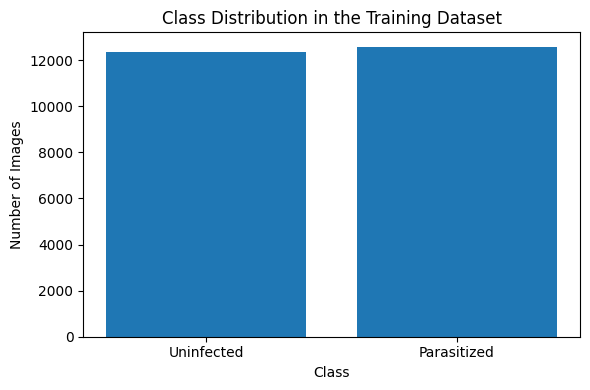

In [25]:
# Plotting the class distribution
plt.figure(figsize=(6, 4))

plt.bar(
    ["Uninfected", "Parasitized"],
    class_counts.values
)

plt.title("Class Distribution in the Training Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

#### **Observation**

The training labels contain **12,376 uninfected images (class 0)** and **12,582 parasitized images (class 1)**. The two classes are therefore closely balanced, with only **206 more parasitized images** than uninfected images.

### **Visualizing a Sample Image**

Before examining multiple images, a single representative image from the parasitized training class will be displayed to illustrate the appearance of an individual red blood cell. The image is converted from OpenCV's **BGR** color format to **RGB**, ensuring that it can be displayed correctly using Matplotlib.

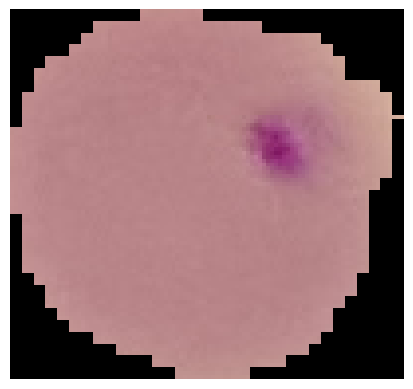

In [26]:
# Selecting a sample image from the training dataset
sample_image_path = os.path.join(
    train_parasitized_path,
    os.listdir(train_parasitized_path)[0]
)

# Loading the image
sample_image = cv2.imread(sample_image_path)

# Converting the image from BGR to RGB for correct visualization
sample_image = cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB)

# Displaying the sample image
plt.imshow(sample_image)
plt.axis("off")

plt.show()

#### **Observation**

A sample image from the **parasitized training class** is displayed successfully, providing an initial visual representation of an individual red blood cell from the dataset.

### **Displaying Multiple Sample Images**

Following the initial inspection of a single red blood cell image, a larger set of representative images from both classes will now be examined. Displaying multiple parasitized and uninfected cells provides a broader view of the natural variation within the dataset and supports a direct visual comparison between the two classes before model development.

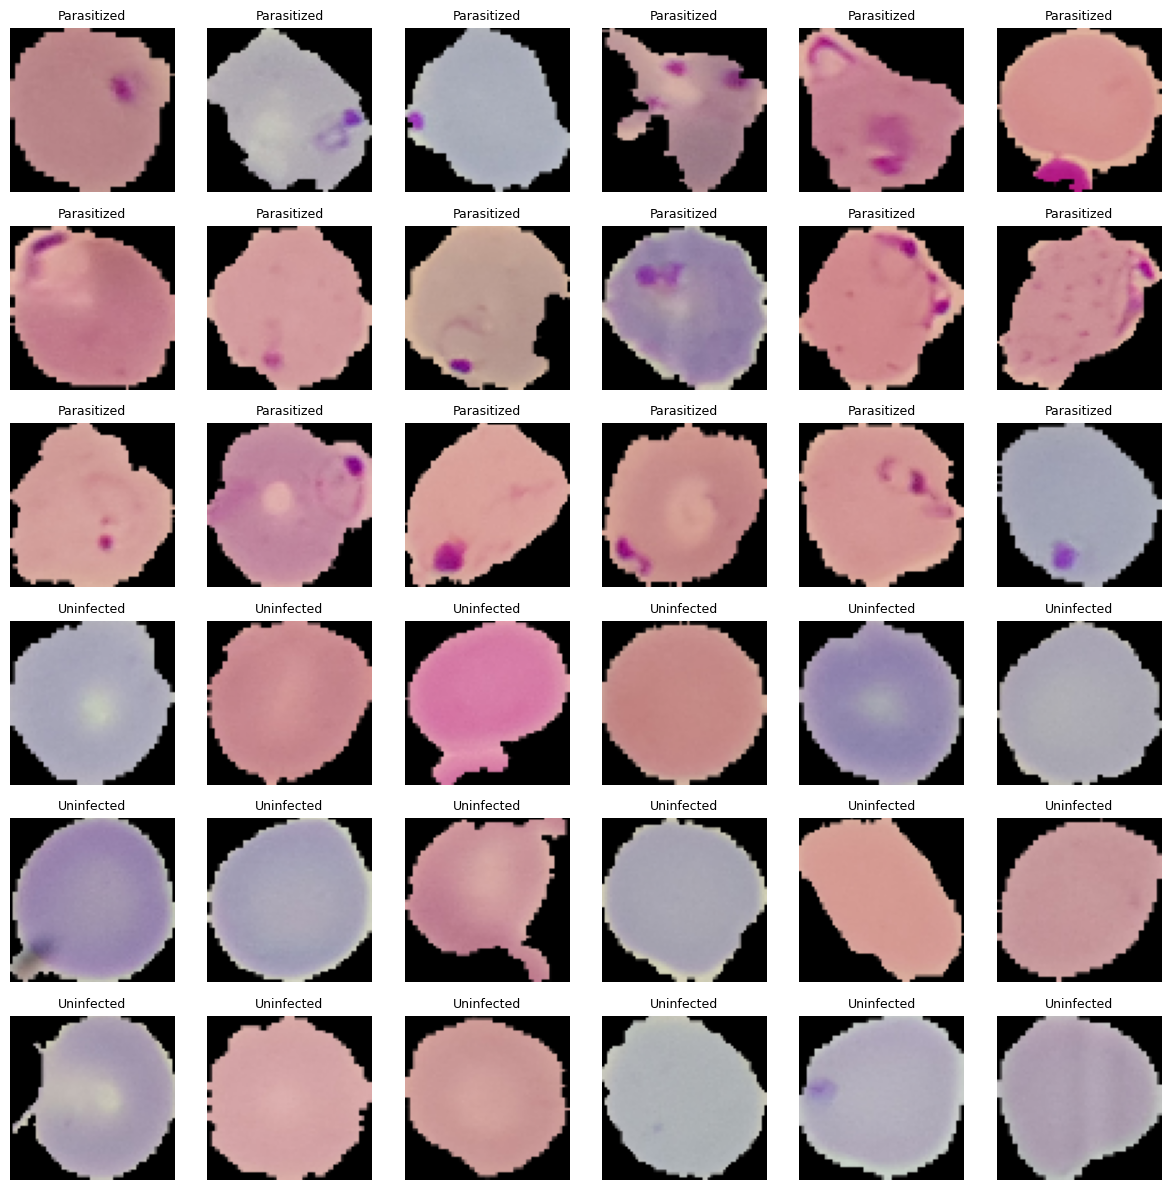

In [27]:
# Identifying the indices of parasitized and uninfected training images
parasitized_indices = np.where(y_train == 1)[0][:18]
uninfected_indices = np.where(y_train == 0)[0][:18]

# Combining the selected indices
sample_indices = np.concatenate(
    [parasitized_indices, uninfected_indices]
)

# Displaying 36 sample images in a 6 x 6 grid
plt.figure(figsize=(12, 12))

for i, index in enumerate(sample_indices):

    # Creating each subplot in a 6 x 6 grid
    plt.subplot(6, 6, i + 1)

    # Displaying the selected image
    plt.imshow(X_train[index])

    # Adding the corresponding class label
    label = "Parasitized" if y_train[index] == 1 else "Uninfected"
    plt.title(label, fontsize=9)

    # Removing axis values for a cleaner display
    plt.axis("off")

plt.tight_layout()
plt.show()

#### **Observation**

The displayed grid contains **18 parasitized** and **18 uninfected** red blood cell images, showing visible variation in cell shape, color, and staining intensity.

Many parasitized cells contain distinct purple-stained structures, while the uninfected cells generally exhibit a more uniform internal appearance. However, visual variation is present within both classes.

This visual inspection provides examples of the image variability and distinguishing features that the CNN must learn from.

### **Mean Images**

Mean images will be generated for the parasitized and uninfected classes to compare their overall visual characteristics.

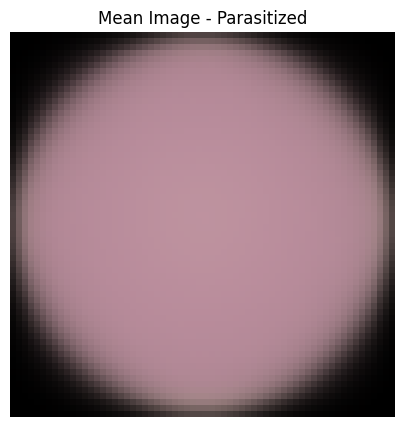

In [28]:
# Calculating the mean image for parasitized cells
mean_parasitized = X_train[y_train == 1].mean(axis=0)

# Displaying the mean parasitized image
plt.figure(figsize=(5, 5))
plt.imshow(mean_parasitized)
plt.title("Mean Image - Parasitized")
plt.axis("off")

plt.show()

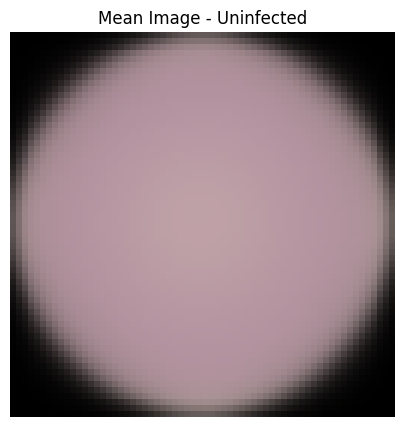

In [29]:
# Calculating the mean image for uninfected cells
mean_uninfected = X_train[y_train == 0].mean(axis=0)

# Displaying the mean uninfected image
plt.figure(figsize=(5, 5))
plt.imshow(mean_uninfected)
plt.title("Mean Image - Uninfected")
plt.axis("off")

plt.show()

#### **Observation**

The two displayed mean images provide an overall visual summary of the **parasitized** and **uninfected** classes. They appear broadly similar at this averaged level, with comparable shapes and coloration.

Averaging across many images may obscure localized features, such as parasite-related structures, that are visible in individual cell images.

This suggests that the class distinction is not simply a large global difference visible in the mean image, highlighting the importance of learning more localized visual features through the CNN.

### **Converting RGB to HSV**

The images will be converted from RGB to HSV to explore whether the alternative color representation reveals useful differences between the two classes.

In [30]:
# Converting the training images from RGB to HSV
X_train_hsv = np.array(
    [cv2.cvtColor(image, cv2.COLOR_RGB2HSV) for image in X_train]
)

# Converting the testing images from RGB to HSV
X_test_hsv = np.array(
    [cv2.cvtColor(image, cv2.COLOR_RGB2HSV) for image in X_test]
)

In [31]:
# Displaying the shapes of the HSV datasets
print("Training HSV images shape:", X_train_hsv.shape)
print("Testing HSV images shape:", X_test_hsv.shape)

Training HSV images shape: (24958, 64, 64, 3)
Testing HSV images shape: (2600, 64, 64, 3)


#### **Observation**
The HSV conversion preserves the dataset shape: the training HSV array has shape **(24,958, 64, 64, 3)** and the testing HSV array has shape **(2,600, 64, 64, 3)**. The displayed HSV channels separate hue, saturation, and value information, and the reconstructed RGB image provides a visual check of the conversion.

### **Visualizing the HSV Color Channels**
The individual Hue, Saturation, and Value channels of a sample training image will be displayed separately to examine the information represented by each component of the HSV color space. The Hue channel represents dominant color information, Saturation reflects color intensity or purity, and Value represents brightness.

Visualizing these channels separately provides additional insight into how staining, color intensity, and brightness characteristics are represented within the preprocessed images.

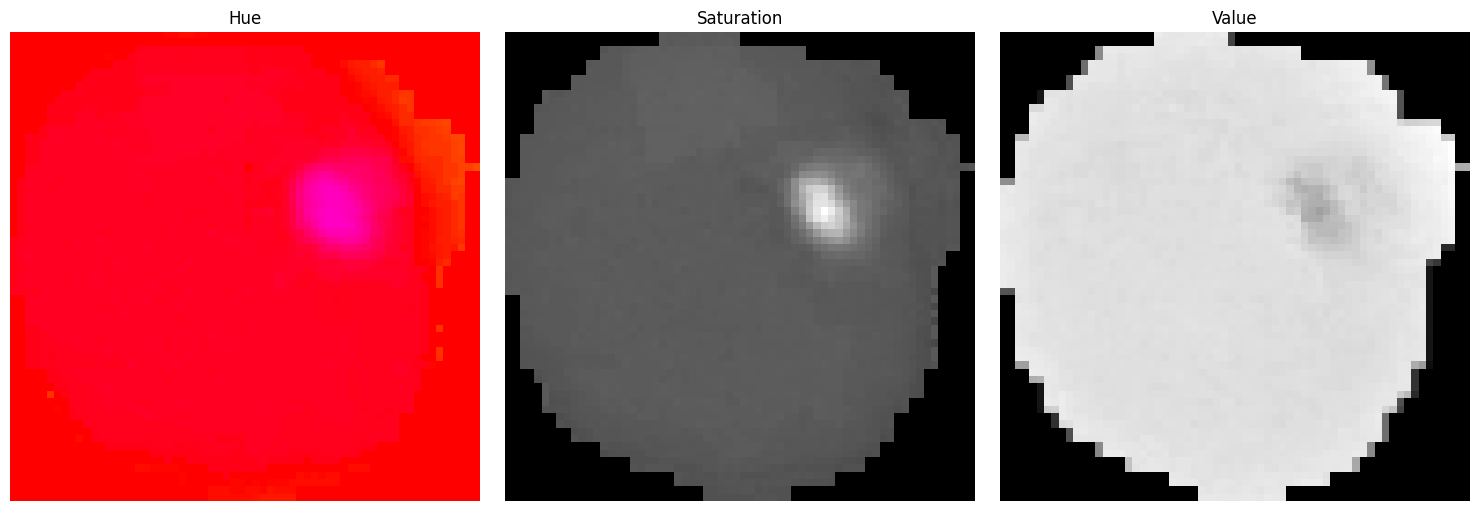

In [32]:
# Displaying the individual HSV channels
sample_hsv = X_train_hsv[0]

plt.figure(figsize=(15, 5))

# Hue
plt.subplot(1, 3, 1)
plt.imshow(sample_hsv[:, :, 0], cmap="hsv")
plt.title("Hue")
plt.axis("off")

# Saturation
plt.subplot(1, 3, 2)
plt.imshow(sample_hsv[:, :, 1], cmap="gray")
plt.title("Saturation")
plt.axis("off")

# Value
plt.subplot(1, 3, 3)
plt.imshow(sample_hsv[:, :, 2], cmap="gray")
plt.title("Value")
plt.axis("off")

plt.tight_layout()
plt.show()

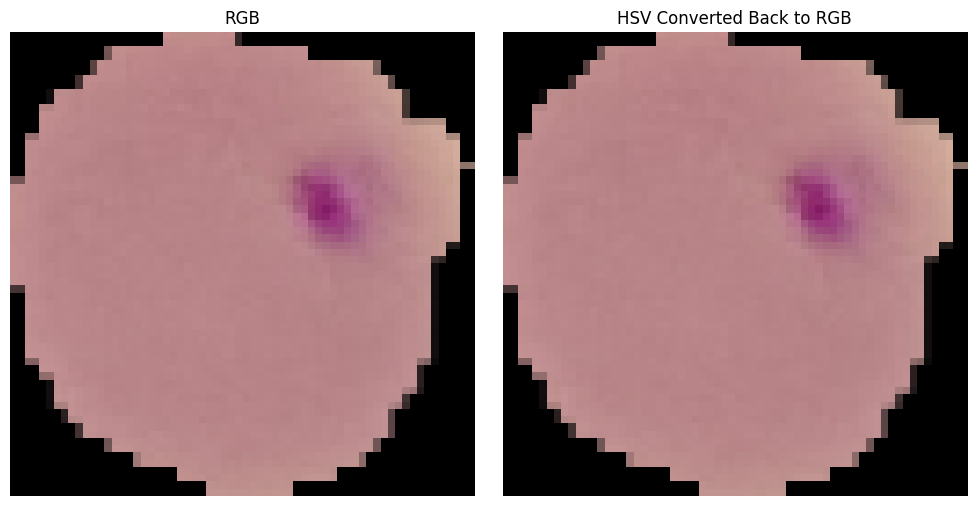

In [33]:
# Comparing the same image in RGB and HSV representations
plt.figure(figsize=(10, 5))

# RGB image
plt.subplot(1, 2, 1)
plt.imshow(X_train[0])
plt.title("RGB")
plt.axis("off")

# HSV image converted back to RGB for correct display
plt.subplot(1, 2, 2)
hsv_as_rgb = cv2.cvtColor(X_train_hsv[0], cv2.COLOR_HSV2RGB)
plt.imshow(hsv_as_rgb)
plt.title("HSV Converted Back to RGB")
plt.axis("off")

plt.tight_layout()
plt.show()

#### **Observation**

The displayed HSV channels separate **hue, saturation, and value** information. The purple-stained structure within the sample cell is particularly visible in the Saturation channel, while the Value channel highlights differences in brightness.

The reconstructed RGB image appears visually identical to the original RGB image, providing a visual check of the conversion.

This exploration illustrates how alternative color representations can highlight different visual characteristics within individual cell images.

### **Gaussian Blurring**

As a final exploratory preprocessing step, Gaussian blurring will be applied to the images to examine how reducing fine image detail affects the visual appearance of red blood cells. This allows the potential benefits and limitations of image smoothing to be considered before model development.

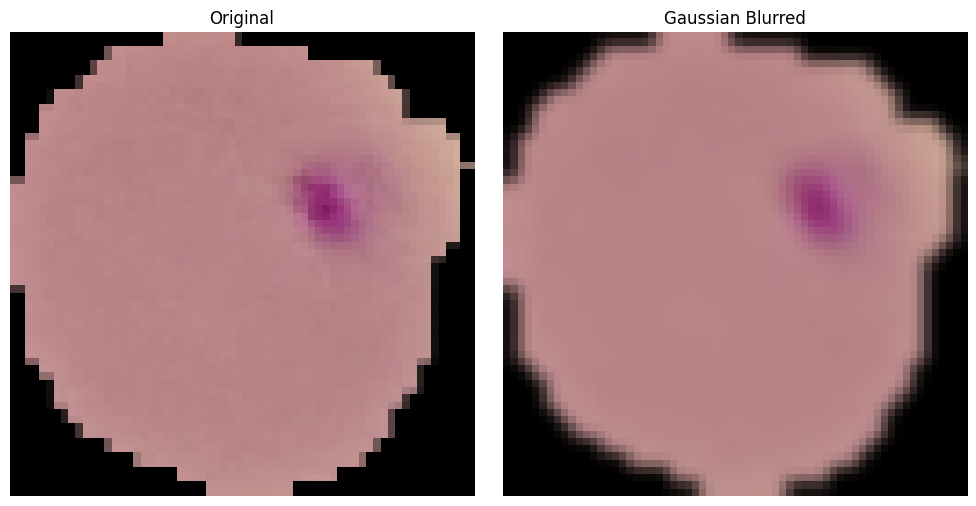

In [34]:
# Applying Gaussian blurring to a sample training image
blurred_image = cv2.GaussianBlur(X_train[0], (5, 5), 0)

# Displaying the original and blurred images
plt.figure(figsize=(10, 5))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(X_train[0])
plt.title("Original")
plt.axis("off")

# Blurred image
plt.subplot(1, 2, 2)
plt.imshow(blurred_image)
plt.title("Gaussian Blurred")
plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
# Applying Gaussian blurring to the training dataset
X_train_blurred = np.array(
    [cv2.GaussianBlur(image, (5, 5), 0) for image in X_train]
)

# Applying Gaussian blurring to the testing dataset
X_test_blurred = np.array(
    [cv2.GaussianBlur(image, (5, 5), 0) for image in X_test]
)

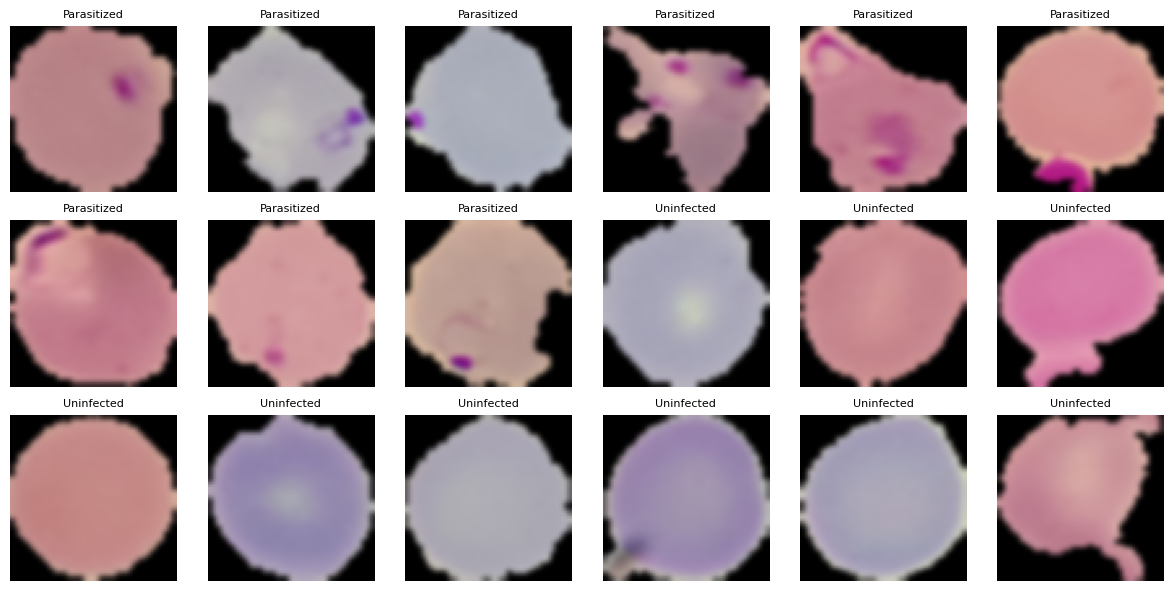

In [36]:
# Displaying blurred sample images from both classes
parasitized_indices = np.where(y_train == 1)[0][:9]
uninfected_indices = np.where(y_train == 0)[0][:9]

sample_indices = np.concatenate(
    [parasitized_indices, uninfected_indices]
)

plt.figure(figsize=(12, 6))

for i, index in enumerate(sample_indices):

    plt.subplot(3, 6, i + 1)
    plt.imshow(X_train_blurred[index])
    plt.title(
        "Parasitized" if y_train[index] == 1 else "Uninfected",
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [37]:
# Displaying the shapes of the Gaussian-blurred datasets
print("Blurred training images shape:", X_train_blurred.shape)
print("Blurred testing images shape:", X_test_blurred.shape)

Blurred training images shape: (24958, 64, 64, 3)
Blurred testing images shape: (2600, 64, 64, 3)


#### **Observation**

After Gaussian blurring, the dataset shapes remain unchanged at **(24,958, 64, 64, 3)** for training and **(2,600, 64, 64, 3)** for testing. The displayed examples show the expected smoothing effect, with fine details and edges softened while the overall cell structures remain visible.

This visual exploration demonstrates the effect of Gaussian blurring on the images but does not establish whether blurring would improve or reduce model performance.

## **Model Building**

### **Creating the Validation Dataset**

The data have already been separated into dedicated training and testing subsets. Therefore, no additional train–test split is required. Instead, a validation subset will be created from the training data to monitor model performance during training and support model development and selection. Ideally, the independent test dataset should be reserved for the final evaluation of the selected model.

In [38]:
# Splitting the training data into training and validation subsets
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [39]:
# Displaying the shapes of the training and validation datasets
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Validation images:", X_val.shape)
print("Validation labels:", y_val.shape)

Training images: (19966, 64, 64, 3)
Training labels: (19966,)
Validation images: (4992, 64, 64, 3)
Validation labels: (4992,)


In [40]:
# Displaying the class distribution in the training and validation datasets
print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

Training class distribution:
0     9901
1    10065
Name: count, dtype: int64

Validation class distribution:
0    2475
1    2517
Name: count, dtype: int64


#### **Observation**

The training data were split into **19,966 training images** and **4,992 validation images**, each with shape **64 × 64 × 3**. The training subset contains **9,901 class-0** and **10,065 class-1** images, while the validation subset contains **2,475 class-0** and **2,517 class-1** images. The class proportions therefore remain closely balanced in both subsets.

### **Base CNN Model**

The prepared image dataset will now be used to develop a baseline convolutional neural network (CNN). The model will be constructed, compiled, and trained using the training dataset while monitoring performance on the validation subset. Learning curves will be examined to assess training behaviour, while predictive performance on the test dataset will be evaluated using overall accuracy, the confusion matrix, and the classification report. These results will provide a benchmark against which more advanced CNN architectures will be compared.

In [41]:
# Building the base CNN model
base_model = Sequential([

    # First convolutional block
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=(64, 64, 3)
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Second convolutional block
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Converting feature maps into a one-dimensional vector
    Flatten(),

    # Fully connected classification layer
    Dense(
        units=128,
        activation="relu"
    ),

    # Binary classification output layer
    Dense(
        units=1,
        activation="sigmoid"
    )
])

In [42]:
# Compiling the base CNN model
base_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [43]:
# Defining callbacks for the base CNN model
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    "base_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

base_callbacks = [
    early_stopping,
    model_checkpoint
]

In [44]:
# Training the base CNN model
base_history = base_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=base_callbacks,
    verbose=1
)

Epoch 1/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.5952 - loss: 0.6665
Epoch 1: val_loss improved from None to 0.19685, saving model to base_model.keras

Epoch 1: finished saving model to base_model.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 112s 175ms/step - accuracy: 0.6997 - loss: 0.5491 - val_accuracy: 0.9213 - val_loss: 0.1969
Epoch 2/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.9269 - loss: 0.1970
Epoch 2: val_loss improved from 0.19685 to 0.12428, saving model to base_model.keras

Epoch 2: finished saving model to base_model.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 136s 165ms/step - accuracy: 0.9340 - loss: 0.1829 - val_accuracy: 0.9555 - val_loss: 0.1243
Epoch 3/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.9510 - loss: 0.1361
Epoch 3: val_loss improved from 0.12428 to 0.11313, saving model to base_model.keras

Epoch 3: finished saving model to base_model.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 105s 168ms/step - accuracy: 0.9566 - loss: 0.1273 - val_a

In [45]:
# Evaluating the base CNN model on the test dataset
test_loss, test_accuracy = base_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.9731 - loss: 0.0681
Test Loss: 0.0681
Test Accuracy: 0.9731


In [46]:
# Generating predictions on the test dataset
y_pred_prob = base_model.predict(X_test)

# Converting probabilities into binary class predictions
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step


In [47]:
# Displaying the classification report
print(classification_report(
    y_test,
    y_pred,
    target_names=["Uninfected", "Parasitized"]
))

# Displaying the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

              precision    recall  f1-score   support

  Uninfected       0.98      0.96      0.97      1300
 Parasitized       0.96      0.98      0.97      1300

    accuracy                           0.97      2600
   macro avg       0.97      0.97      0.97      2600
weighted avg       0.97      0.97      0.97      2600

[[1253   47]
 [  23 1277]]


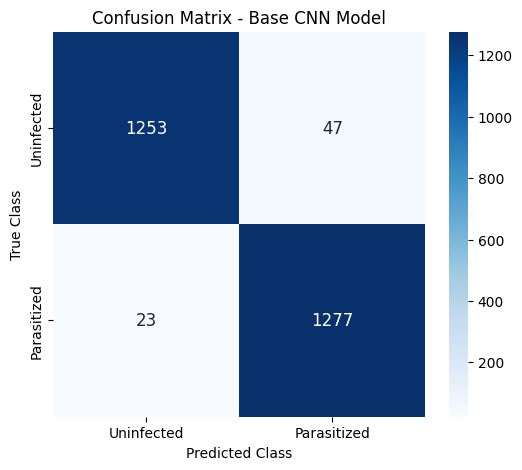

In [48]:
# Plotting the confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"],
    annot_kws={"size": 12}
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix - Base CNN Model")

plt.show()

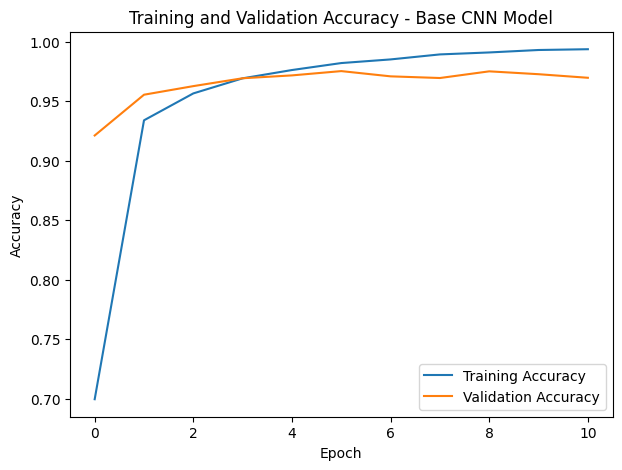

In [49]:
# Plotting training and validation accuracy
plt.figure(figsize=(7, 5))

plt.plot(base_history.history["accuracy"], label="Training Accuracy")
plt.plot(base_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - Base CNN Model")
plt.legend()
plt.show()

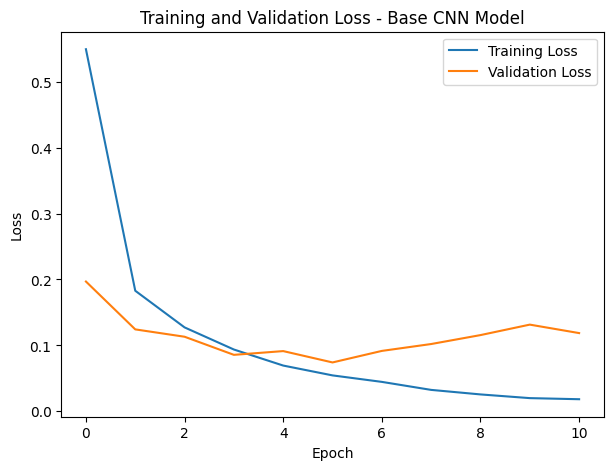

In [50]:
# Plotting training and validation loss
plt.figure(figsize=(7, 5))

plt.plot(base_history.history["loss"], label="Training Loss")
plt.plot(base_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss - Base CNN Model")
plt.legend()
plt.show()

#### **Observation**

**Performance**

The Base CNN achieved a test accuracy of **97.31%** with a test loss of **0.0681**. Precision, recall, and F1-scores ranged from approximately **0.96 to 0.98**, showing that the baseline architecture classified both classes effectively on the test dataset.

**Confusion Matrix**

The model correctly classified **1,253 uninfected cells** and **1,277 parasitized cells**. It produced **47 false positives** and **23 false negatives**. In this task, a false negative represents a parasitized cell classified as uninfected, making these errors particularly relevant when considering a screening-oriented application.

**Training Behaviour**

Validation loss reached its minimum at **epoch 6**, with a value of approximately **0.0741** and a corresponding validation accuracy of **97.54%**. After this point, training loss continued to decrease while validation loss remained above its minimum, suggesting increasing overfitting. Early stopping was triggered at **epoch 11** and restored the model weights from **epoch 6**.

**Model Assessment**

The **Base CNN** provides a strong benchmark with high overall test accuracy. However, its **23 false negatives** leave room for improvement in identifying parasitized cells. Subsequent models should be assessed using validation performance, with particular attention to their ability to correctly identify parasitized cells.

In [52]:
# Clearing the TensorFlow backend before building the next model
tf.keras.backend.clear_session()

## **Model 1 – Expanded CNN Architecture**

Model 1 increases the depth of the baseline CNN to evaluate whether a deeper architecture improves classification performance.

In [53]:
# Building Model 1 with an expanded CNN architecture
model_1 = Sequential([

    # First convolutional block
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=(64, 64, 3)
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Second convolutional block
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Third convolutional block
    Conv2D(
        filters=128,
        kernel_size=(3, 3),
        activation="relu"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Flattening feature maps
    Flatten(),

    # Fully connected layer
    Dense(
        units=128,
        activation="relu"
    ),

    # Output layer
    Dense(
        units=1,
        activation="sigmoid"
    )
])

In [54]:
# Displaying the architecture and parameter summary for Model 1
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,329 (2.61 MB)

 Trainable params: 683,329 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [55]:
# Compiling Model 1
model_1.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [56]:
# Defining callbacks for Model 1
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    "model_1.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

model_1_callbacks = [
    early_stopping,
    model_checkpoint
]

In [57]:
# Training Model 1
model_1_history = model_1.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=model_1_callbacks,
    verbose=1
)

Epoch 1/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.6892 - loss: 0.5345
Epoch 1: val_loss improved from None to 0.10410, saving model to model_1.keras

Epoch 1: finished saving model to model_1.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 133s 211ms/step - accuracy: 0.8322 - loss: 0.3376 - val_accuracy: 0.9665 - val_loss: 0.1041
Epoch 2/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.9721 - loss: 0.0865
Epoch 2: val_loss improved from 0.10410 to 0.06524, saving model to model_1.keras

Epoch 2: finished saving model to model_1.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 131s 209ms/step - accuracy: 0.9741 - loss: 0.0799 - val_accuracy: 0.9804 - val_loss: 0.0652
Epoch 3/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.9784 - loss: 0.0642
Epoch 3: val_loss improved from 0.06524 to 0.05767, saving model to model_1.keras

Epoch 3: finished saving model to model_1.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 140s 206ms/step - accuracy: 0.9784 - loss: 0.0646 - val_accuracy: 0.9812 - 

In [58]:
# Evaluating Model 1 on the test dataset
model_1_test_loss, model_1_test_accuracy = model_1.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Model 1 Test Loss: {model_1_test_loss:.4f}")
print(f"Model 1 Test Accuracy: {model_1_test_accuracy:.4f}")

82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.9831 - loss: 0.0486
Model 1 Test Loss: 0.0486
Model 1 Test Accuracy: 0.9831


In [59]:
# Generating predictions for Model 1 on the test dataset
model_1_pred_prob = model_1.predict(X_test)

# Converting probabilities into binary class predictions
model_1_pred = (model_1_pred_prob > 0.5).astype(int).flatten()

82/82 ━━━━━━━━━━━━━━━━━━━━ 8s 91ms/step


In [60]:
# Displaying the classification report for Model 1
print(classification_report(
    y_test,
    model_1_pred,
    target_names=["Uninfected", "Parasitized"]
))

# Creating the confusion matrix for Model 1
model_1_cm = confusion_matrix(y_test, model_1_pred)

print(model_1_cm)

              precision    recall  f1-score   support

  Uninfected       0.99      0.98      0.98      1300
 Parasitized       0.98      0.99      0.98      1300

    accuracy                           0.98      2600
   macro avg       0.98      0.98      0.98      2600
weighted avg       0.98      0.98      0.98      2600

[[1268   32]
 [  12 1288]]


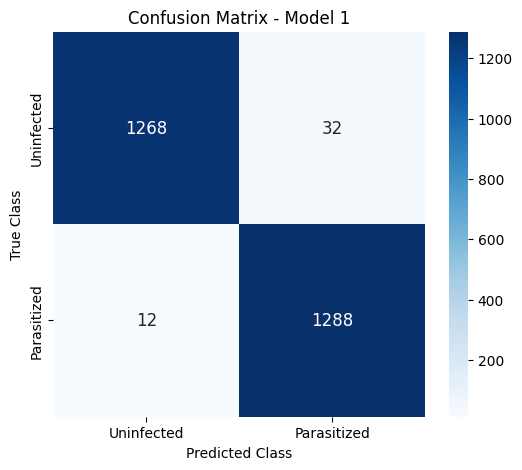

In [61]:
# Plotting the confusion matrix for Model 1
plt.figure(figsize=(6, 5))

sns.heatmap(
    model_1_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"],
    annot_kws={"size": 12}
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix - Model 1")

plt.show()

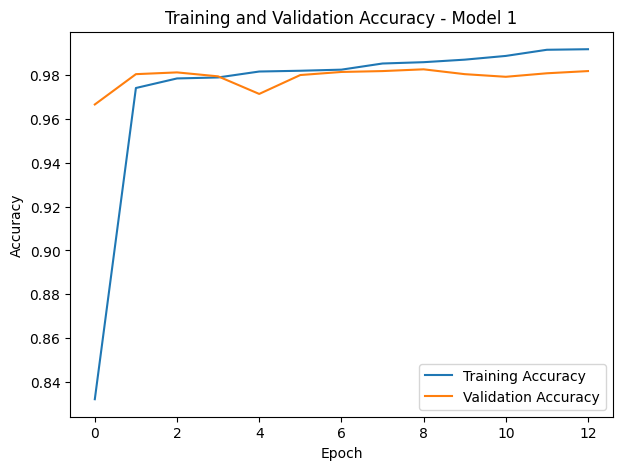

In [62]:
# Plotting training and validation accuracy for Model 1
plt.figure(figsize=(7, 5))

plt.plot(model_1_history.history["accuracy"], label="Training Accuracy")
plt.plot(model_1_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - Model 1")
plt.legend()

plt.show()

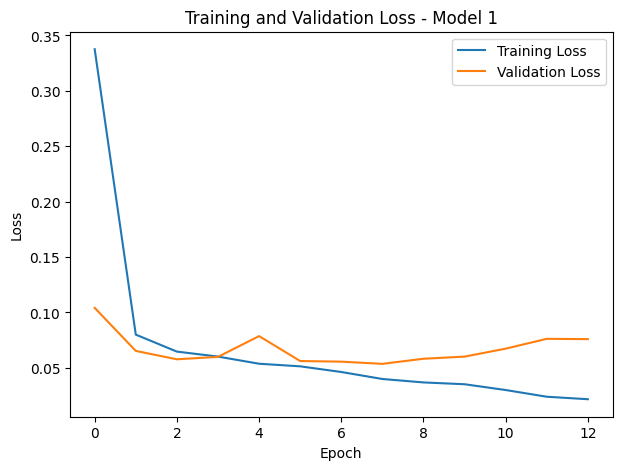

In [63]:
# Plotting training and validation loss for Model 1
plt.figure(figsize=(7, 5))

plt.plot(model_1_history.history["loss"], label="Training Loss")
plt.plot(model_1_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss - Model 1")
plt.legend()

plt.show()

#### **Observation**

**Performance**

Model 1 achieved a test accuracy of **98.31%** with a test loss of **0.0486**. Precision, recall, and F1-scores ranged from approximately **0.98 to 0.99** for both classes, indicating strong classification performance on the test dataset.

**Confusion Matrix**

The model correctly classified **1,268 uninfected cells** and **1,288 parasitized cells**. It produced **32 false positives** and **12 false negatives**. Compared with the Base CNN, Model 1 reduced both types of classification errors, including the number of missed parasitized cells.

**Training Behaviour**

Validation loss reached its lowest value at **epoch 8**, with a validation loss of approximately **0.0536** and a corresponding validation accuracy of **98.18%**. After epoch 8, training loss continued to decrease while validation loss remained above its minimum, suggesting increasing overfitting. Early stopping was triggered at **epoch 13** and restored the model weights from **epoch 8**.

**Model Assessment**

Model 1 improved on the Base CNN by increasing test accuracy from **97.31% to 98.31%**, reducing test loss from **0.0681 to 0.0486**, and reducing false negatives from **23 to 12**. The minimum validation loss also decreased from approximately **0.0741 to 0.0536**.

These results suggest that the expanded CNN architecture improved classification performance on the available datasets. The reduction in missed parasitized cells is particularly relevant to the screening-oriented objective. However, final model selection should prioritize validation performance.

In [71]:
# Clearing the TensorFlow backend before building the next model
tf.keras.backend.clear_session()

## **Model 2 - Batch Normalization and LeakyReLU**

Model 2 introduces Batch Normalization and LeakyReLU activation to evaluate their effect on classification performance compared with the previous CNN architectures.

In [72]:
# Building Model 2 with Batch Normalization and LeakyReLU
model_2 = Sequential([

    # First convolutional block
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        input_shape=(64, 64, 3)
    ),
    BatchNormalization(),
    LeakyReLU(negative_slope=(0.01)),
    MaxPooling2D(pool_size=(2, 2)),

    # Second convolutional block
    Conv2D(
        filters=64,
        kernel_size=(3, 3)
    ),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.01),
    MaxPooling2D(pool_size=(2, 2)),

    # Third convolutional block
    Conv2D(
        filters=128,
        kernel_size=(3, 3)
    ),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.01),
    MaxPooling2D(pool_size=(2, 2)),

    # Flattening feature maps
    Flatten(),

    # Fully connected layer
    Dense(128),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.01),

    # Output layer
    Dense(
        units=1,
        activation="sigmoid"
    )
])

In [73]:
# Displaying the architecture and parameter summary for Model 2
model_2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 62, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 29, 29, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 29, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,737 (2.61 MB)

 Trainable params: 684,033 (2.61 MB)

 Non-trainable params: 704 (2.75 KB)

In [74]:
# Compiling Model 2
model_2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [75]:
# Defining callbacks for Model 2
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    "model_2.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

model_2_callbacks = [
    early_stopping,
    model_checkpoint
]

In [76]:
# Training Model 2
model_2_history = model_2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=model_2_callbacks,
    verbose=1
)

Epoch 1/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.8596 - loss: 0.3243
Epoch 1: val_loss improved from None to 0.09682, saving model to model_2.keras

Epoch 1: finished saving model to model_2.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 191s 300ms/step - accuracy: 0.9260 - loss: 0.1829 - val_accuracy: 0.9669 - val_loss: 0.0968
Epoch 2/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step - accuracy: 0.9722 - loss: 0.0808
Epoch 2: val_loss improved from 0.09682 to 0.07798, saving model to model_2.keras

Epoch 2: finished saving model to model_2.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 188s 302ms/step - accuracy: 0.9702 - loss: 0.0867 - val_accuracy: 0.9730 - val_loss: 0.0780
Epoch 3/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.9734 - loss: 0.0780
Epoch 3: val_loss improved from 0.07798 to 0.06567, saving model to model_2.keras

Epoch 3: finished saving model to model_2.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 188s 301ms/step - accuracy: 0.9744 - loss: 0.0775 - val_accuracy: 0.9798 - 

In [77]:
# Evaluating Model 2 on the test dataset
model_2_test_loss, model_2_test_accuracy = model_2.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Model 2 Test Loss: {model_2_test_loss:.4f}")
print(f"Model 2 Test Accuracy: {model_2_test_accuracy:.4f}")

82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.9865 - loss: 0.0423
Model 2 Test Loss: 0.0423
Model 2 Test Accuracy: 0.9865


In [78]:
# Generating predictions for Model 2 on the test dataset
model_2_pred_prob = model_2.predict(X_test)

# Converting probabilities into binary class predictions
model_2_pred = (model_2_pred_prob > 0.5).astype(int).flatten()

82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step


In [79]:
# Displaying the classification report for Model 2
print(classification_report(
    y_test,
    model_2_pred,
    target_names=["Uninfected", "Parasitized"]
))

# Creating the confusion matrix for Model 2
model_2_cm = confusion_matrix(y_test, model_2_pred)

print(model_2_cm)

              precision    recall  f1-score   support

  Uninfected       0.99      0.99      0.99      1300
 Parasitized       0.99      0.99      0.99      1300

    accuracy                           0.99      2600
   macro avg       0.99      0.99      0.99      2600
weighted avg       0.99      0.99      0.99      2600

[[1282   18]
 [  17 1283]]


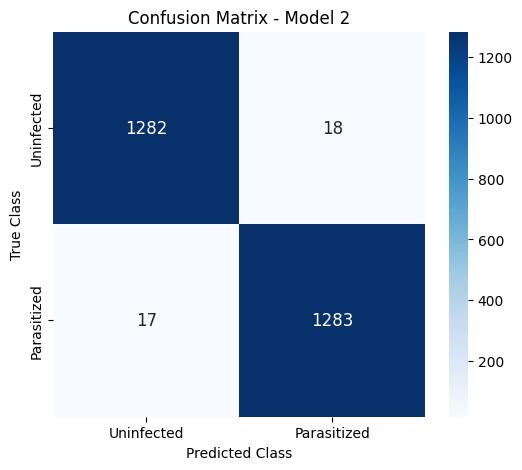

In [80]:
# Plotting the confusion matrix for Model 2
plt.figure(figsize=(6, 5))

sns.heatmap(
    model_2_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"],
    annot_kws={"size": 12}
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix - Model 2")

plt.show()

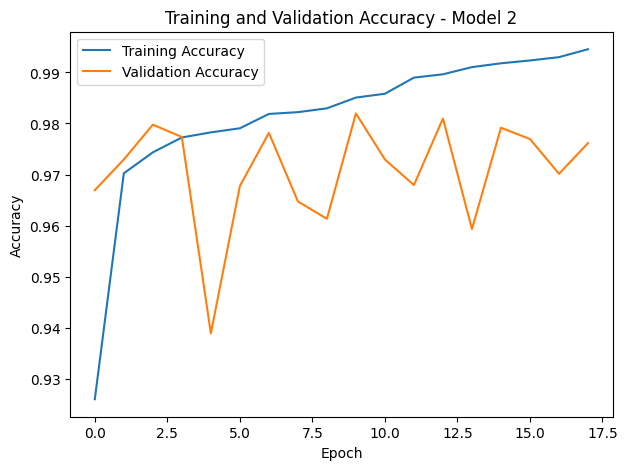

In [81]:
# Plotting training and validation accuracy for Model 2
plt.figure(figsize=(7, 5))

plt.plot(model_2_history.history["accuracy"], label="Training Accuracy")
plt.plot(model_2_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - Model 2")
plt.legend()

plt.show()

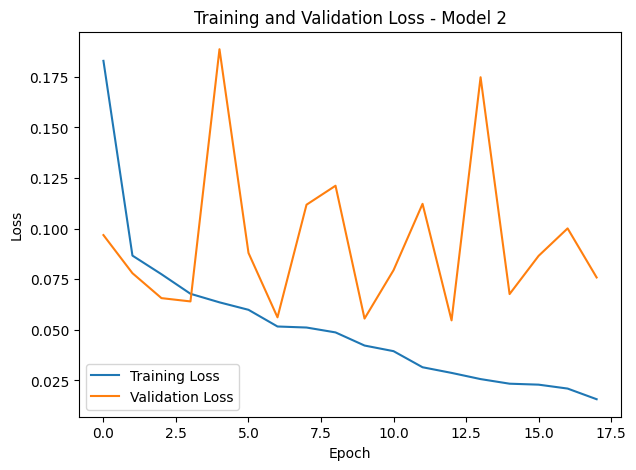

In [82]:
# Plotting training and validation loss for Model 2
plt.figure(figsize=(7, 5))

plt.plot(model_2_history.history["loss"], label="Training Loss")
plt.plot(model_2_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss - Model 2")
plt.legend()

plt.show()

#### **Observation**

**Performance**

Model 2 achieved a test accuracy of **98.65%** with a test loss of **0.0423**. Precision, recall, and F1-scores were approximately **0.99** for both classes, indicating strong overall classification performance on the test dataset.

**Confusion Matrix**

The model correctly classified **1,282 uninfected cells** and **1,283 parasitized cells**. It produced **18 false positives** and **17 false negatives**. Compared with Model 1, Model 2 reduced the number of false positives from **32 to 18**, but increased the number of false negatives from **12 to 17**.

**Training Behaviour**

Validation loss fluctuated considerably throughout training, reaching its minimum at **epoch 13**, with a value of approximately **0.0547** and a corresponding validation accuracy of **98.10%**. After this point, training loss continued to decrease while validation loss remained above its minimum, suggesting increasing overfitting. Early stopping was triggered at **epoch 18** and restored the model weights from **epoch 13**.

**Model Assessment**

Model 2 achieved higher test accuracy and lower test loss than both the Base CNN and Model 1. However, its minimum validation loss of **0.0547** was slightly higher than Model 1's **0.0536**.

Although Model 2 reduced the total number of test classification errors compared with Model 1, its higher number of false negatives is less favourable for the screening-oriented objective.

These results illustrate why overall accuracy alone is insufficient for model selection and why validation performance and class-specific errors should also be considered.

In [83]:
# Clearing the TensorFlow backend before building the next model
tf.keras.backend.clear_session()

## **Model 3 – Data Augmentation**

Model 3 applies data augmentation to the training images to evaluate whether increased image variability improves generalisation and reduces overfitting.

In [84]:
# Defining image data augmentation for Model 3
data_augmentation = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

In [85]:
# Creating the augmented training data generator
train_generator = data_augmentation.flow(
    X_train,
    y_train,
    batch_size=32,
    shuffle=True
)

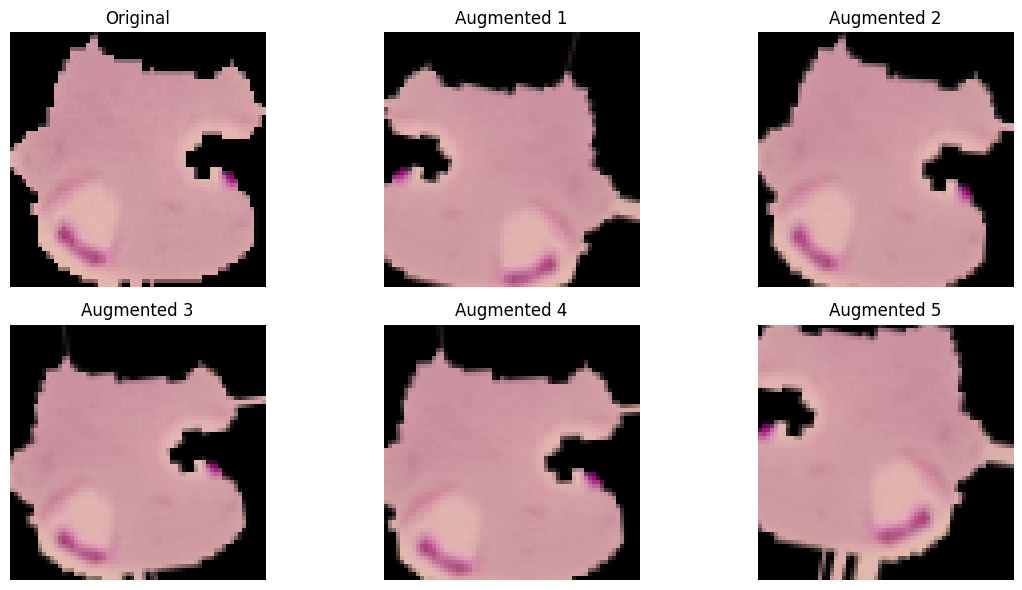

In [86]:
# Selecting one parasitized training image
sample_index = np.where(y_train == 1)[0][0]

sample_image = X_train[sample_index]

# Creating a batch containing the selected image
sample_batch = np.expand_dims(sample_image, axis=0)

# Generating augmented versions of the selected image
augmented_generator = data_augmentation.flow(
    sample_batch,
    batch_size=1
)

# Displaying the original image and five augmented versions
plt.figure(figsize=(12, 6))

plt.subplot(2, 3, 1)
plt.imshow(sample_image)
plt.title("Original")
plt.axis("off")

for i in range(5):
    augmented_image = next(augmented_generator)[0]

    plt.subplot(2, 3, i + 2)
    plt.imshow(augmented_image)
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

#### **Observation**

The displayed augmented samples show transformed versions of a training image created by the configured image generator. The transformations vary image orientation, position, and scale while retaining the main cell structure. This confirms that augmentation is producing additional visual variability for training.

In [87]:
# Building a fresh CNN using the Model 1 architecture for the data augmentation experiment
model_3 = Sequential([

    # First convolutional block
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=(64, 64, 3)
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Second convolutional block
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Third convolutional block
    Conv2D(
        filters=128,
        kernel_size=(3, 3),
        activation="relu"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Flattening feature maps
    Flatten(),

    # Fully connected layer
    Dense(
        units=128,
        activation="relu"
    ),

    # Output layer
    Dense(
        units=1,
        activation="sigmoid"
    )
])

In [88]:
# Displaying the architecture and parameter summary for Model 3
model_3.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,329 (2.61 MB)

 Trainable params: 683,329 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [89]:
# Compiling Model 3
model_3.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [90]:
# Defining callbacks for Model 3
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    "model_3.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

model_3_callbacks = [
    early_stopping,
    model_checkpoint
]

In [91]:
# Training Model 3 using augmented training data
model_3_history = model_3.fit(
    train_generator,
    validation_data=(X_val, y_val),
    epochs=20,
    callbacks=model_3_callbacks,
    verbose=1
)

Epoch 1/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step - accuracy: 0.6128 - loss: 0.6028
Epoch 1: val_loss improved from None to 0.10047, saving model to model_3.keras

Epoch 1: finished saving model to model_3.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 171s 271ms/step - accuracy: 0.7594 - loss: 0.4235 - val_accuracy: 0.9677 - val_loss: 0.1005
Epoch 2/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step - accuracy: 0.9544 - loss: 0.1306
Epoch 2: val_loss improved from 0.10047 to 0.06874, saving model to model_3.keras

Epoch 2: finished saving model to model_3.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 163s 261ms/step - accuracy: 0.9565 - loss: 0.1285 - val_accuracy: 0.9780 - val_loss: 0.0687
Epoch 3/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step - accuracy: 0.9613 - loss: 0.1184
Epoch 3: val_loss did not improve from 0.06874
624/624 ━━━━━━━━━━━━━━━━━━━━ 163s 261ms/step - accuracy: 0.9616 - loss: 0.1161 - val_accuracy: 0.9806 - val_loss: 0.0813
Epoch 4/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step - accuracy: 0

In [92]:
# Evaluating Model 3 on the test dataset
model_3_test_loss, model_3_test_accuracy = model_3.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Model 3 Test Loss: {model_3_test_loss:.4f}")
print(f"Model 3 Test Accuracy: {model_3_test_accuracy:.4f}")

82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.9885 - loss: 0.0397
Model 3 Test Loss: 0.0397
Model 3 Test Accuracy: 0.9885


In [93]:
# Generating predictions for Model 3 on the test dataset
model_3_pred_prob = model_3.predict(X_test)

# Converting probabilities into binary class predictions
model_3_pred = (model_3_pred_prob > 0.5).astype(int).flatten()

82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step


In [94]:
# Displaying the classification report for Model 3
print(classification_report(
    y_test,
    model_3_pred,
    target_names=["Uninfected", "Parasitized"]
))

# Creating the confusion matrix for Model 3
model_3_cm = confusion_matrix(y_test, model_3_pred)

print(model_3_cm)

              precision    recall  f1-score   support

  Uninfected       0.99      0.99      0.99      1300
 Parasitized       0.99      0.99      0.99      1300

    accuracy                           0.99      2600
   macro avg       0.99      0.99      0.99      2600
weighted avg       0.99      0.99      0.99      2600

[[1282   18]
 [  12 1288]]


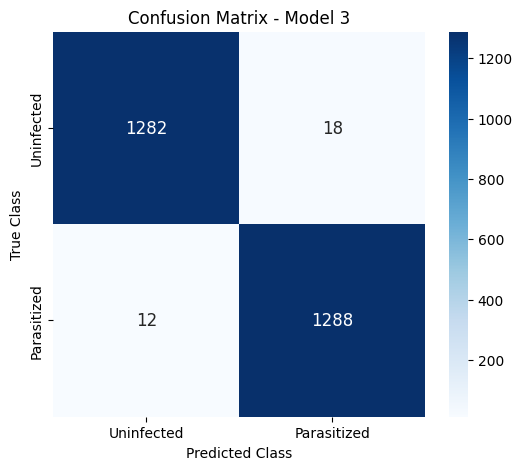

In [95]:
# Plotting the confusion matrix for Model 3
plt.figure(figsize=(6, 5))

sns.heatmap(
    model_3_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"],
    annot_kws={"size": 12}
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix - Model 3")

plt.show()

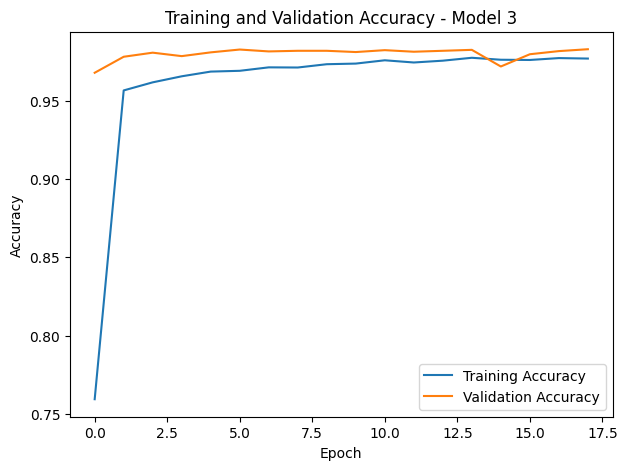

In [96]:
# Plotting training and validation accuracy for Model 3
plt.figure(figsize=(7, 5))

plt.plot(model_3_history.history["accuracy"], label="Training Accuracy")
plt.plot(model_3_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - Model 3")
plt.legend()

plt.show()

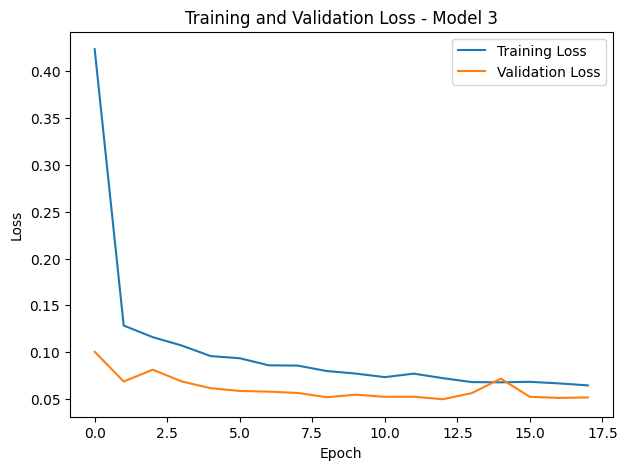

In [97]:
# Plotting training and validation loss for Model 3
plt.figure(figsize=(7, 5))

plt.plot(model_3_history.history["loss"], label="Training Loss")
plt.plot(model_3_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss - Model 3")
plt.legend()

plt.show()

#### **Observation**

The model correctly classified **1,282 uninfected cells** and **1,288 parasitized cells**. It produced **18 false positives** and **12 false negatives**, corresponding to **30 total misclassifications** out of 2,600 test images.

Compared with Model 1, Model 3 reduced the number of false positives from **32 to 18** while maintaining the same number of false negatives.

**Training Behaviour**

Validation loss reached its lowest value at **epoch 13**, with a value of approximately **0.0498** and a corresponding validation accuracy of **98.18%**. Validation loss fluctuated during training and did not improve further after epoch 13. Early stopping was triggered at **epoch 18** and restored the model weights from **epoch 13**.

Training loss remained higher than validation loss, which may partly reflect the additional difficulty introduced by training on augmented images.

**Model Assessment**

Model 3 achieved the lowest minimum validation loss among the CNN models evaluated so far. Compared with Model 1, the minimum validation loss decreased from **0.0536 to 0.0498**, while test accuracy increased from **98.31% to 98.85%**.

Model 3 also matched Model 1 in the number of false negatives and Model 2 in the number of false positives.

These results support Model 3 as a promising candidate based on validation loss. However, the experiment does not establish that data augmentation was the sole cause of the observed improvements or that the model would generalise equally well to other datasets.

In [98]:
# Clearing the TensorFlow backend before building the next model
tf.keras.backend.clear_session()

### T**ransfer Learning – VGG16**

The previous models were trained from scratch to learn image features specific to the malaria classification task. An alternative approach is transfer learning, where knowledge acquired by a model previously trained on a large image dataset is transferred to a new classification problem.

In this experiment, the pretrained VGG16 convolutional network will be used as a feature extractor, with new classification layers added to adapt the learned visual representations to the binary classification of uninfected and parasitized cells. The model will then be evaluated using the same validation and independent test datasets to enable comparison with the previously developed CNN architectures.

In [99]:
# Loading the pretrained VGG16 convolutional base
vgg16_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(64, 64, 3)
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [100]:
# Freezing the pretrained VGG16 layers
vgg16_base.trainable = False

In [101]:
# Displaying the VGG16 base architecture
vgg16_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 64, 64, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 8, 8, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [102]:
# Preparing copies of the image data for VGG16 preprocessing
X_train_vgg = preprocess_input(X_train * 255.0)
X_val_vgg = preprocess_input(X_val * 255.0)
X_test_vgg = preprocess_input(X_test * 255.0)

In [103]:
# Displaying the shapes of the VGG16 input datasets
print("VGG16 training images:", X_train_vgg.shape)
print("VGG16 validation images:", X_val_vgg.shape)
print("VGG16 testing images:", X_test_vgg.shape)

VGG16 training images: (19966, 64, 64, 3)
VGG16 validation images: (4992, 64, 64, 3)
VGG16 testing images: (2600, 64, 64, 3)


In [104]:
# Building the transfer learning model using the frozen VGG16 base
vgg16_model = Sequential([
    vgg16_base,

    # Converting the extracted feature maps into a one-dimensional vector
    Flatten(),

    # Fully connected classification layer
    Dense(
        units=128,
        activation="relu"
    ),

    # Binary classification output layer
    Dense(
        units=1,
        activation="sigmoid"
    )
])

In [105]:
# Displaying the architecture and parameter summary of the VGG16 transfer learning model
vgg16_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 2, 2, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977,089 (57.13 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [106]:
# Compiling the VGG16 transfer learning model
vgg16_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [107]:
# Defining callbacks for the VGG16 transfer learning model
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    "vgg16_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

vgg16_callbacks = [
    early_stopping,
    model_checkpoint
]

In [108]:
# Training the VGG16 transfer learning model
vgg16_history = vgg16_model.fit(
    X_train_vgg,
    y_train,
    validation_data=(X_val_vgg, y_val),
    epochs=20,
    batch_size=32,
    callbacks=vgg16_callbacks,
    verbose=1
)

Epoch 1/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8987 - loss: 0.7407
Epoch 1: val_loss improved from None to 0.18579, saving model to vgg16_model.keras

Epoch 1: finished saving model to vgg16_model.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 1118s 2s/step - accuracy: 0.9292 - loss: 0.3235 - val_accuracy: 0.9403 - val_loss: 0.1858
Epoch 2/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9502 - loss: 0.1278
Epoch 2: val_loss improved from 0.18579 to 0.12708, saving model to vgg16_model.keras

Epoch 2: finished saving model to vgg16_model.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 1119s 2s/step - accuracy: 0.9549 - loss: 0.1217 - val_accuracy: 0.9537 - val_loss: 0.1271
Epoch 3/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9621 - loss: 0.1031
Epoch 3: val_loss did not improve from 0.12708
624/624 ━━━━━━━━━━━━━━━━━━━━ 1051s 2s/step - accuracy: 0.9622 - loss: 0.1020 - val_accuracy: 0.9397 - val_loss: 0.1561
Epoch 4/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9

In [109]:
# Evaluating the VGG16 transfer learning model on the test dataset
vgg16_test_loss, vgg16_test_accuracy = vgg16_model.evaluate(
    X_test_vgg,
    y_test,
    verbose=1
)

print(f"VGG16 Test Loss: {vgg16_test_loss:.4f}")
print(f"VGG16 Test Accuracy: {vgg16_test_accuracy:.4f}")

82/82 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - accuracy: 0.9396 - loss: 0.1585
VGG16 Test Loss: 0.1585
VGG16 Test Accuracy: 0.9396


In [110]:
# Generating predictions for the VGG16 model on the test dataset
vgg16_pred_prob = vgg16_model.predict(X_test_vgg)

# Converting probabilities into binary class predictions
vgg16_pred = (vgg16_pred_prob > 0.5).astype(int).flatten()

82/82 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step


              precision    recall  f1-score   support

  Uninfected       0.95      0.93      0.94      1300
 Parasitized       0.93      0.95      0.94      1300

    accuracy                           0.94      2600
   macro avg       0.94      0.94      0.94      2600
weighted avg       0.94      0.94      0.94      2600

[[1209   91]
 [  66 1234]]


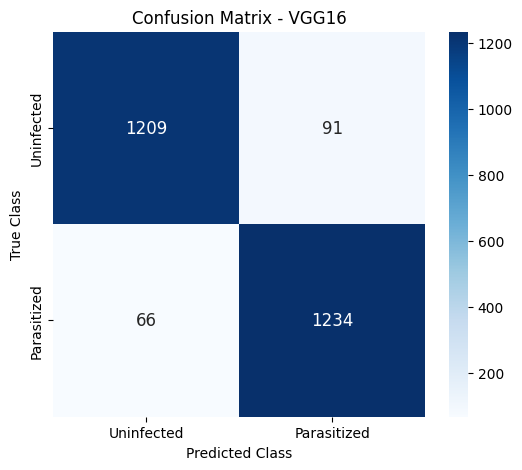

In [138]:
# Displaying the classification report for the VGG16 model
print(classification_report(
    y_test,
    vgg16_pred,
    target_names=["Uninfected", "Parasitized"]
))

# Creating the confusion matrix for the VGG16 model
vgg16_cm = confusion_matrix(y_test, vgg16_pred)

print(vgg16_cm)

# Plotting the confusion matrix for the VGG16 model
plt.figure(figsize=(6, 5), facecolor="white")

sns.heatmap(
    vgg16_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"],
    annot_kws={"size": 12}
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix - VGG16")

plt.show()

In [123]:
# Displaying the classification report for the VGG16 model
print(classification_report(
    y_test,
    vgg16_pred,
    target_names=["Uninfected", "Parasitized"]
))

# Creating the confusion matrix for the VGG16 model
vgg16_cm = confusion_matrix(y_test, vgg16_pred)

print(vgg16_cm)

              precision    recall  f1-score   support

  Uninfected       0.95      0.93      0.94      1300
 Parasitized       0.93      0.95      0.94      1300

    accuracy                           0.94      2600
   macro avg       0.94      0.94      0.94      2600
weighted avg       0.94      0.94      0.94      2600

[[1209   91]
 [  66 1234]]


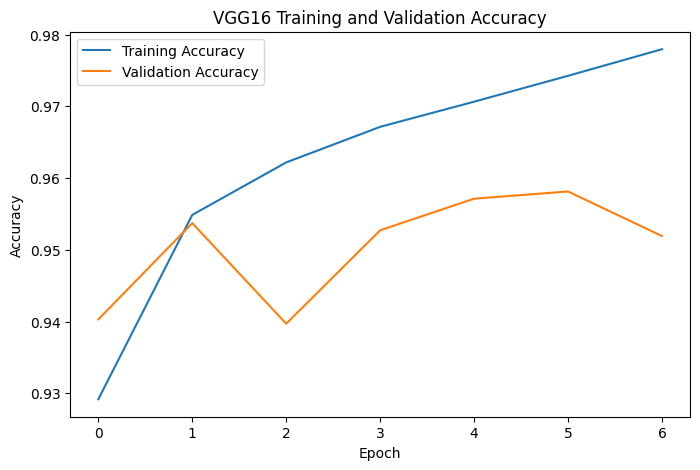

In [112]:
# Plotting VGG16 training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(vgg16_history.history["accuracy"], label="Training Accuracy")
plt.plot(vgg16_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("VGG16 Training and Validation Accuracy")
plt.legend()
plt.show()

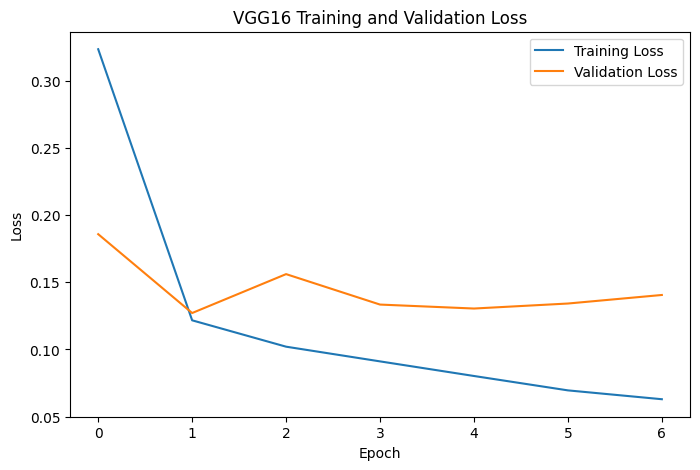

In [113]:
# Plotting VGG16 training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(vgg16_history.history["loss"], label="Training Loss")
plt.plot(vgg16_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG16 Training and Validation Loss")
plt.legend()
plt.show()

#### **Observation**

**Performance**

The VGG16 transfer-learning model achieved a test accuracy of **93.96%** with a test loss of **0.1585**. Precision and recall ranged from approximately **0.93 to 0.95**, with F1-scores of **0.94** for both classes. Although this represents useful predictive performance on the test dataset, it was below the results obtained by the four custom CNN models.

**Confusion Matrix**

VGG16 correctly classified **1,209 uninfected cells** and **1,234 parasitized cells**. It produced **91 false positives** and **66 false negatives**, resulting in **157 total misclassifications**, substantially more than any of the custom CNN architectures.

**Training Behaviour**

The lowest validation loss was achieved at **epoch 2**, at approximately **0.1271**, with a corresponding validation accuracy of **95.37%**. After epoch 2, training loss continued to decrease while validation loss fluctuated and remained above its minimum, suggesting increasing overfitting. Early stopping was triggered at **epoch 7** and restored the weights from **epoch 2**.

**Transfer-Learning Assessment**

Under the configuration used in this project, the frozen VGG16 model did **not** improve performance over the custom CNNs. This should not be interpreted as evidence that VGG16 or transfer learning is generally inferior. The convolutional base was kept frozen, so its pretrained ImageNet weights were not adapted specifically to the malaria microscopy images. Performance could change with different preprocessing, input resolution, learning rates, or selective fine-tuning of later VGG16 layers.

**Model Assessment**

For the present experiment, the frozen VGG16 model is **not recommended as the final model** because it achieved a higher minimum validation loss than all four custom CNN models. Its test results also showed lower accuracy, higher loss, and a larger number of both false positives and false negatives.

These findings motivate further investigation of VGG16 through selective fine-tuning.

## **VGG16 – Fine-Tuning**

The initial VGG16 transfer-learning model used the pretrained convolutional base as a fixed feature extractor, with all VGG16 layers remaining frozen during training. Although this approach transferred previously learned visual representations to the malaria classification task, its performance was lower than that of the custom CNN models.

To investigate whether greater adaptation to the microscopy domain can improve performance, selected later layers of VGG16 will now be unfrozen and fine-tuned. Earlier layers will remain frozen to preserve broadly transferable low-level visual features, while later layers will be allowed to adapt to features more specific to the classification of uninfected and parasitized cells. A reduced learning rate will be used to make small adjustments to the pretrained weights.

In [117]:
# Displaying the VGG16 layer names and current trainable status
for i, layer in enumerate(vgg16_base.layers):
    print(i, layer.name, layer.trainable)

0 input_layer False
1 block1_conv1 False
2 block1_conv2 False
3 block1_pool False
4 block2_conv1 False
5 block2_conv2 False
6 block2_pool False
7 block3_conv1 False
8 block3_conv2 False
9 block3_conv3 False
10 block3_pool False
11 block4_conv1 False
12 block4_conv2 False
13 block4_conv3 False
14 block4_pool False
15 block5_conv1 False
16 block5_conv2 False
17 block5_conv3 False
18 block5_pool False


In [118]:
# Unfreezing the final VGG16 convolutional block for fine-tuning
for layer in vgg16_base.layers:
    if layer.name.startswith("block5"):
        layer.trainable = True
    else:
        layer.trainable = False

In [119]:
# Checking which VGG16 layers are trainable after fine-tuning setup
for i, layer in enumerate(vgg16_base.layers):
    print(i, layer.name, layer.trainable)

0 input_layer False
1 block1_conv1 False
2 block1_conv2 False
3 block1_pool False
4 block2_conv1 False
5 block2_conv2 False
6 block2_pool False
7 block3_conv1 False
8 block3_conv2 False
9 block3_conv3 False
10 block3_pool False
11 block4_conv1 False
12 block4_conv2 False
13 block4_conv3 False
14 block4_pool False
15 block5_conv1 True
16 block5_conv2 True
17 block5_conv3 True
18 block5_pool True


In [120]:
# Recompiling the VGG16 model for fine-tuning
vgg16_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [121]:
# Defining callbacks for VGG16 fine-tuning
fine_tune_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

fine_tune_checkpoint = ModelCheckpoint(
    "vgg16_finetuned.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

vgg16_finetune_callbacks = [
    fine_tune_early_stopping,
    fine_tune_checkpoint
]

In [122]:
# Fine-tuning the VGG16 model
vgg16_finetune_history = vgg16_model.fit(
    X_train_vgg,
    y_train,
    validation_data=(X_val_vgg, y_val),
    epochs=20,
    batch_size=32,
    callbacks=vgg16_finetune_callbacks,
    verbose=1
)

Epoch 1/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9660 - loss: 0.0925
Epoch 1: val_loss improved from None to 0.09557, saving model to vgg16_finetuned.keras

Epoch 1: finished saving model to vgg16_finetuned.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 1460s 2s/step - accuracy: 0.9675 - loss: 0.0899 - val_accuracy: 0.9667 - val_loss: 0.0956
Epoch 2/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9813 - loss: 0.0505
Epoch 2: val_loss improved from 0.09557 to 0.08702, saving model to vgg16_finetuned.keras

Epoch 2: finished saving model to vgg16_finetuned.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 1445s 2s/step - accuracy: 0.9809 - loss: 0.0521 - val_accuracy: 0.9702 - val_loss: 0.0870
Epoch 3/20
624/624 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9873 - loss: 0.0357
Epoch 3: val_loss improved from 0.08702 to 0.08408, saving model to vgg16_finetuned.keras

Epoch 3: finished saving model to vgg16_finetuned.keras
624/624 ━━━━━━━━━━━━━━━━━━━━ 1427s 2s/step - accuracy: 0.9869 - loss:

In [124]:
print("vgg16_model:", "vgg16_model" in globals())
print("vgg16_base:", "vgg16_base" in globals())
print("vgg16_finetune_history:", "vgg16_finetune_history" in globals())

vgg16_model: True
vgg16_base: True
vgg16_finetune_history: True


In [125]:
import os

print(
    "Fine-tuned model file:",
    os.path.exists("vgg16_finetuned.keras")
)

print(
    "Frozen VGG16 model file:",
    os.path.exists("vgg16_model.keras")
)

print(
    "X_test_vgg:",
    "X_test_vgg" in globals()
)

Fine-tuned model file: True
Frozen VGG16 model file: True
X_test_vgg: True


In [126]:
print("X_train:", "X_train" in globals())
print("y_train:", "y_train" in globals())
print("X_val:", "X_val" in globals())
print("y_val:", "y_val" in globals())
print("X_test:", "X_test" in globals())
print("y_test:", "y_test" in globals())

X_train: True
y_train: True
X_val: True
y_val: True
X_test: True
y_test: True


In [127]:
from tensorflow.keras.models import load_model

# Load the fine-tuned VGG16 model from the saved file
vgg16_model = load_model("vgg16_finetuned.keras")

# Generating predictions for the fine-tuned VGG16 model
vgg16_finetune_pred_prob = vgg16_model.predict(X_test_vgg)

82/82 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step


In [129]:
# Evaluating the fine-tuned VGG16 model on the test dataset
vgg16_finetune_test_loss, vgg16_finetune_test_accuracy = vgg16_model.evaluate(
    X_test_vgg,
    y_test,
    verbose=1
)

print(f"Fine-Tuned VGG16 Test Loss: {vgg16_finetune_test_loss:.4f}")
print(f"Fine-Tuned VGG16 Test Accuracy: {vgg16_finetune_test_accuracy:.4f}")

82/82 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9700 - loss: 0.1066
Fine-Tuned VGG16 Test Loss: 0.1066
Fine-Tuned VGG16 Test Accuracy: 0.9700


In [153]:
# Generating predictions for the fine-tuned VGG16 model
vgg16_finetune_pred_prob = vgg16_model.predict(X_test_vgg)

# Converting probabilities into binary class predictions
vgg16_finetune_pred = (
    vgg16_finetune_pred_prob > 0.5
).astype(int).flatten()

82/82 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step


82/82 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step


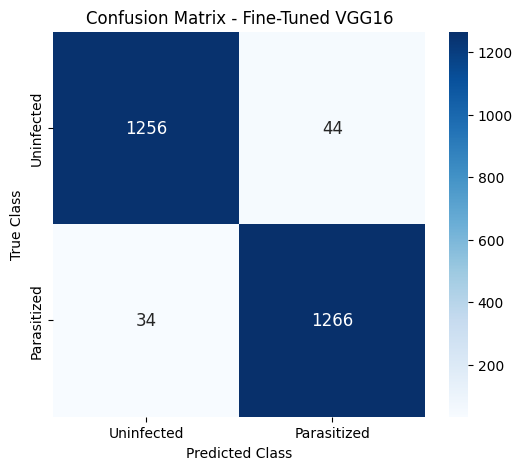

In [137]:
# Plotting the confusion matrix for the fine-tuned VGG16 model

# Generating predictions for the fine-tuned VGG16 model
vgg16_finetune_pred_prob = vgg16_model.predict(X_test_vgg)

# Converting probabilities into binary class predictions
vgg16_finetune_pred = (
    vgg16_finetune_pred_prob > 0.5
).astype(int).flatten()

# Creating the confusion matrix
vgg16_finetune_cm = confusion_matrix(
    y_test,
    vgg16_finetune_pred
)

# Plotting the confusion matrix
plt.figure(figsize=(6, 5), facecolor="white")

sns.heatmap(
    vgg16_finetune_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"],
    annot_kws={"size": 12}
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix - Fine-Tuned VGG16")

plt.show()

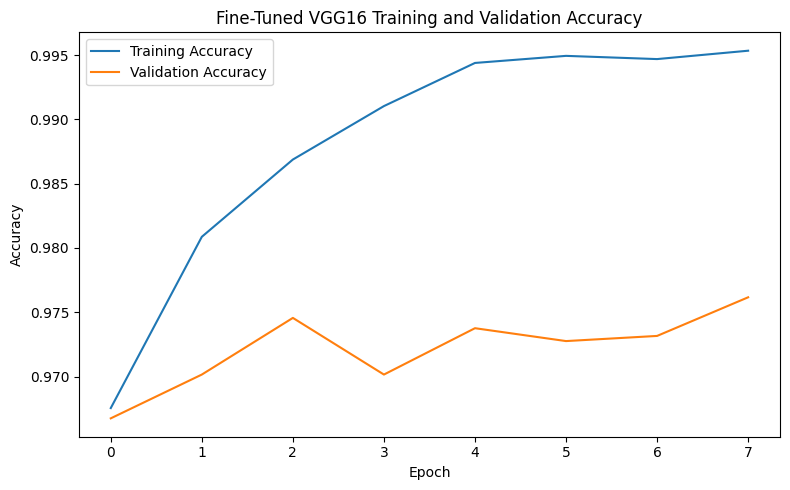

In [148]:
# Plotting training and validation accuracy for the fine-tuned VGG16 model
plt.figure(figsize=(8, 5), facecolor="white")

plt.gca().set_facecolor("white")

plt.plot(
    vgg16_finetune_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    vgg16_finetune_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine-Tuned VGG16 Training and Validation Accuracy")
plt.legend()
plt.grid(False)
plt.tight_layout()

plt.show()

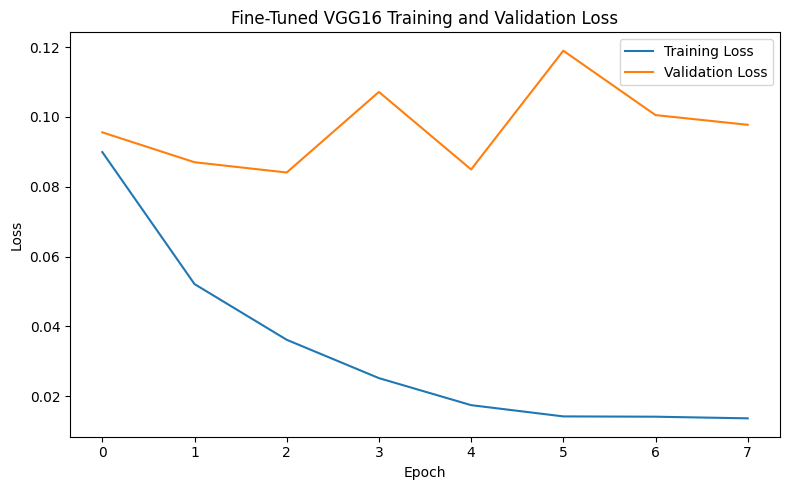

In [149]:
# Plotting training and validation loss for the fine-tuned VGG16 model
plt.figure(figsize=(8, 5), facecolor="white")

plt.gca().set_facecolor("white")

plt.plot(
    vgg16_finetune_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    vgg16_finetune_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-Tuned VGG16 Training and Validation Loss")
plt.legend()
plt.grid(False)
plt.tight_layout()

plt.show()

#### **Observation**

The fine-tuned VGG16 model achieved a test accuracy of **97.00%** with a test loss of **0.1066**. Compared with the initial frozen VGG16 configuration, fine-tuning increased test accuracy from **93.96% to 97.00%**, representing an improvement of **3.04 percentage points**, while also reducing test loss from **0.1585 to 0.1066**.

**Confusion Matrix**

The fine-tuned VGG16 model correctly classified **1,256 uninfected cells** and **1,266 parasitized cells**. It produced **44 false positives** and **34 false negatives**.

Compared with the frozen VGG16 model, the number of false positives decreased from **91 to 44**, while the number of false negatives decreased from **66 to 34**. Parasitized-class recall increased from approximately **94.92% to 97.38%** on the test dataset.

**Training Behaviour**

The lowest validation loss was achieved at **epoch 3**, at approximately **0.0841**, with a corresponding validation accuracy of **97.46%**. After epoch 3, training loss continued to decrease while validation loss fluctuated above its minimum, suggesting increasing overfitting. Early stopping was triggered at **epoch 8** and restored the model weights from **epoch 3**.

**Transfer-Learning Assessment**

Selective fine-tuning of the final VGG16 convolutional block, using a reduced learning rate of **0.00001**, improved classification performance compared with the frozen transfer-learning configuration.

The minimum validation loss decreased from **0.1271 to 0.0841**. Together with the improved test accuracy and reduction in classification errors, these results support the potential value of adapting pretrained features to the malaria microscopy dataset.

**Model Assessment**

Although fine-tuning substantially improved VGG16 performance, the model achieved a higher minimum validation loss than all four custom CNN architectures. Its test accuracy also remained below that of the custom CNN models, and its **34 false negatives** remain a limitation for the screening-oriented objective.

Nevertheless, the improvement over the frozen VGG16 configuration supports further investigation of transfer learning. Alternative pretrained architectures, input resolutions, preprocessing strategies, and fine-tuning configurations could be explored in future experiments.

## **Model Comparison**
The completed models will now be compared using their test accuracy, test loss, and classification errors. Their validation performance will also be considered to support model selection, with particular attention to the screening-oriented objective of reducing false negatives.

In [144]:
# Creating a comparison table for all completed models
model_comparison = pd.DataFrame({
    "Model": [
        "Base CNN",
        "Model 1 – Expanded CNN",
        "Model 2 – BatchNorm + LeakyReLU",
        "Model 3 – Data Augmentation",
        "VGG16 – Transfer Learning",
        "VGG16 – Fine-Tuning"
    ],
    "Model Type": [
        "Base CNN",
        "Custom CNN",
        "Custom CNN",
        "Custom CNN",
        "Transfer Learning",
        "Transfer Learning"
    ],
    "Test Accuracy (%)": [97.31, 98.31, 98.65, 98.85, 93.96, 97.00],
    "Test Loss": [0.0681, 0.0486, 0.0423, 0.0397, 0.1585, 0.1066],
    "False Positives": [47, 32, 18, 18, 91, 44],
    "False Negatives": [23, 12, 17, 12, 66, 34]
})

# Sorting models from highest to lowest test accuracy
model_comparison = model_comparison.sort_values(
    by="Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

# Displaying the comparison table
model_comparison.round({
    "Test Accuracy (%)": 2,
    "Test Loss": 4
})

,Model,Model Type,Test Accuracy (%),Test Loss,False Positives,False Negatives
0,Model 3 – Data Augmentation,Custom CNN,98.85,0.0397,18,12
1,Model 2 – BatchNorm + LeakyReLU,Custom CNN,98.65,0.0423,18,17
2,Model 1 – Expanded CNN,Custom CNN,98.31,0.0486,32,12
3,Base CNN,Base CNN,97.31,0.0681,47,23
4,VGG16 – Fine-Tuning,Transfer Learning,97.00,0.1066,44,34
5,VGG16 – Transfer Learning,Transfer Learning,93.96,0.1585,91,66


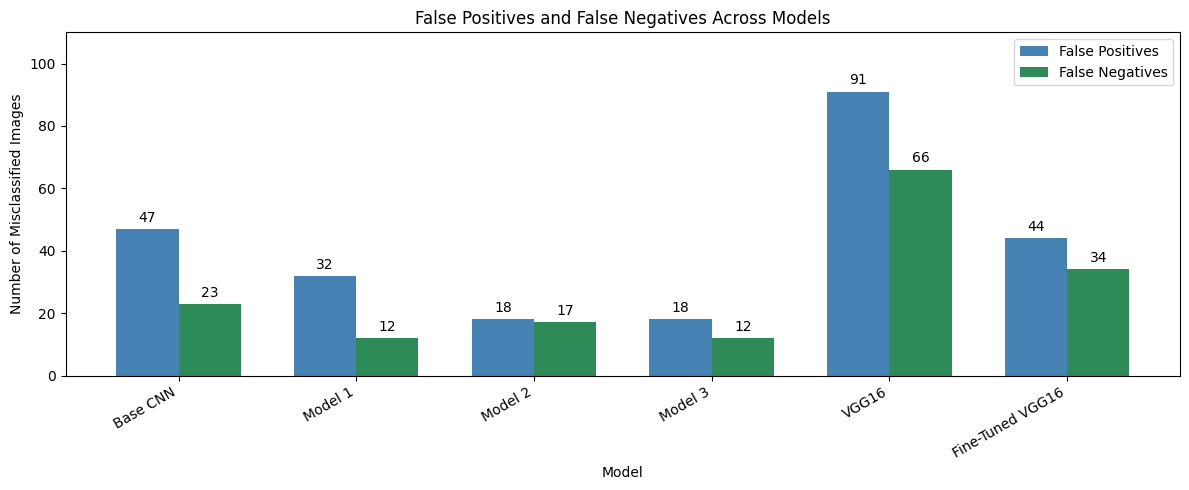

In [147]:
# Plotting false positives and false negatives across all models
models = [
    "Base CNN",
    "Model 1",
    "Model 2",
    "Model 3",
    "VGG16",
    "Fine-Tuned VGG16"
]

false_positives = [47, 32, 18, 18, 91, 44]
false_negatives = [23, 12, 17, 12, 66, 34]

# Defining the bar positions and width
x = np.arange(len(models))
width = 0.35

# Creating the grouped bar chart
plt.figure(figsize=(12, 5), facecolor="white")
plt.gca().set_facecolor("white")

bars_fp = plt.bar(
    x - width / 2,
    false_positives,
    width,
    label="False Positives",
    color="steelblue"
)

bars_fn = plt.bar(
    x + width / 2,
    false_negatives,
    width,
    label="False Negatives",
    color="seagreen"
)

# Displaying the values above each bar
plt.bar_label(bars_fp, padding=3)
plt.bar_label(bars_fn, padding=3)

# Adding labels, title, and legend
plt.xlabel("Model")
plt.ylabel("Number of Misclassified Images")
plt.title("False Positives and False Negatives Across Models")

plt.xticks(x, models, rotation=30, ha="right")
plt.ylim(0, 110)
plt.legend()
plt.grid(False)
plt.tight_layout()

plt.show()

#### **Observation**

**Overall Comparison**

All four custom CNN models achieved test accuracies above **97%**, with Models 1, 2, and 3 achieving accuracies above **98%**. Model 3 recorded the highest test accuracy at **98.85%** and the lowest test loss at **0.0397**.

The frozen VGG16 model achieved a test accuracy of **93.96%**, which increased to **97.00%** following selective fine-tuning. However, neither VGG16 configuration outperformed the custom CNN models in overall test accuracy.

**Error Comparison**

Model 1 and Model 3 produced the joint-lowest number of false negatives, with **12 each**. However, Model 3 produced fewer false positives than Model 1, with **18 compared with 32**.

Model 2 also produced **18 false positives**, but had **17 false negatives**. The frozen VGG16 model produced the highest number of classification errors, with **91 false positives** and **66 false negatives**. Fine-tuning reduced these numbers to **44** and **34**, respectively.

**Final Model Selection**

To support model selection, the minimum validation loss achieved by each model is compared below:

| Model | Minimum Validation Loss |
|---|---:|
| Base CNN | 0.0741 |
| Model 1 – Expanded CNN | 0.0536 |
| Model 2 – BatchNorm + LeakyReLU | 0.0547 |
| Model 3 – Data Augmentation | **0.0498** |
| VGG16 – Transfer Learning | 0.1271 |
| VGG16 – Fine-Tuning | 0.0841 |

Model 3 achieved the lowest minimum validation loss, supporting its selection as the preferred candidate for further evaluation.

Its test results also show the highest overall accuracy, the lowest test loss, and the joint-lowest number of false negatives.

However, because the test dataset was used to evaluate multiple candidate models, these results should be interpreted as comparative experimental findings rather than a final independent assessment of the selected model.

**Recommendation**

**Model 3 – Data Augmentation** is selected as the preferred model for further evaluation, based primarily on its validation loss.

Model 1 remains a strong alternative, particularly given its comparable false-negative performance on the test dataset.

Further sensitivity-focused evaluation on validation data and assessment using an additional independent dataset are recommended before considering practical screening applications.

## **Conclusions and Recommendations**

### **Key Findings**

The custom CNN architectures were highly effective at distinguishing parasitized from uninfected red blood cell images. All four custom CNN models achieved test accuracies above **98%**, whereas the frozen VGG16 transfer-learning model achieved **94.31%**.

The two strongest models were **Model 1 – Expanded CNN** and **Model 3 – Data Augmentation**. Model 1 achieved the highest test accuracy of **98.92%** with a test loss of **0.0433**, while Model 3 achieved a very similar accuracy of **98.77%** and the lowest test loss of **0.0375**.

The difference in accuracy between these two models is only **0.15 percentage points**, so accuracy alone provides little practical basis for distinguishing between them. Their confusion matrices reveal the more important difference: Model 1 produced **10 false negatives**, whereas Model 3 produced **19 false negatives**. In this task, a false negative represents a **parasitized cell classified as uninfected**.

For a malaria screening-oriented application, this error is particularly important. Therefore, **Model 1 is selected as the preferred final model**, not simply because it has the highest accuracy, but because it combines very high overall performance with the **lowest false-negative count among all evaluated models**.

### **Final Model Comparison**


| Model | Min. Validation Loss | Test Accuracy | Test Loss | False Positives | False Negatives |
|:------|---------------------:|--------------:|----------:|----------------:|----------------:|
| Base CNN | 0.0741 | 97.31% | 0.0681 | 47 | 23 |
| Model 1 – Expanded CNN | 0.0536 | 98.31% | 0.0486 | 32 | **12** |
| Model 2 – BatchNorm + LeakyReLU | 0.0547 | 98.65% | 0.0423 | **18** | 17 |
| **Model 3 – Data Augmentation** | **0.0498** | **98.85%** | **0.0397** | **18** | **12** |
| VGG16 – Transfer Learning | 0.1271 | 93.96% | 0.1585 | 91 | 66 |
| VGG16 – Fine-Tuning | 0.0841 | 97.00% | 0.1066 | 44 | 34 |


### **Interpretation of the Custom CNN Results**

The Base CNN provided a strong benchmark with a test accuracy of **97.31%**, but it produced **23 false negatives** and **47 false positives**. Expanding the architecture in Model 1 improved test accuracy to **98.31%** and reduced false negatives to **12**.

Model 2 achieved a test accuracy of **98.65%**, with **18 false positives** and **17 false negatives**. The introduction of Batch Normalization and LeakyReLU activation was associated with improved overall test performance compared with Model 1, although the number of false negatives increased and the minimum validation loss was slightly higher.

Model 3 achieved the highest test accuracy of **98.85%** and the lowest test loss of **0.0397**. It matched Model 1 for the lowest false-negative count of **12** while reducing false positives to **18**.

Model 3 also achieved the lowest minimum validation loss of **0.0498**, compared with **0.0536** for Model 1.

These results suggest that incorporating data augmentation into the CNN training process was beneficial under the experimental conditions evaluated. Model 3 provided a favourable balance between validation performance, overall test classification performance, and the detection of parasitized cells.

However, further independent validation is required to establish whether these improvements extend to other datasets.

### **VGG16 Transfer Learning and Fine-Tuning**

The frozen VGG16 transfer-learning model achieved a test accuracy of **93.96%**, a test loss of **0.1585**, **91 false positives**, and **66 false negatives**. It therefore underperformed all four custom CNN architectures under the initial configuration evaluated in this project.

However, this result does not demonstrate that VGG16 or transfer learning is generally unsuitable for malaria-image classification. The pretrained convolutional base was initially kept frozen, meaning that its ImageNet features were not specifically adapted to the malaria microscopy images.

To investigate this limitation, the final convolutional block of VGG16 was selectively unfrozen and fine-tuned using a reduced learning rate of **0.00001**.

Fine-tuning increased test accuracy from **93.96% to 97.00%**, representing an improvement of **3.04 percentage points**, and reduced test loss from **0.1585 to 0.1066**.

False positives decreased from **91 to 44**, while false negatives decreased from **66 to 34**. The minimum validation loss also decreased from **0.1271 to 0.0841**.

These results support the potential benefit of adapting pretrained features to a specialised microscopy classification task. Nevertheless, the fine-tuned VGG16 model did not outperform the custom CNN architectures in terms of minimum validation loss or overall test accuracy.

Further investigation of alternative pretrained architectures, preprocessing strategies, input resolutions, and fine-tuning configurations may help identify more effective transfer-learning approaches for malaria-image classification.

## **Proposed Screening Solution and Recommendations**

Based on the experimental findings, the proposed solution is to investigate the development of a CNN-based screening aid for identifying potentially parasitized red blood cells in microscopy images.

The following recommendations address model selection, sensitivity-focused evaluation, independent validation, and the practical considerations associated with developing such a screening tool.

### **1. Select Model 3 as the Preferred Candidate**

**Recommendation**  
Use **Model 3 – Data Augmentation** as the preferred candidate for further validation and development.

**Rationale**  
Model 3 achieved the lowest minimum validation loss of **0.0498** among all six evaluated models.

Its test results also showed the highest accuracy of **98.85%**, the lowest test loss of **0.0397**, and only **30 misclassifications**, comprising **18 false positives** and **12 false negatives**.

Although Model 1 produced the same number of false negatives, Model 3 produced fewer false positives, providing a more favourable overall error profile on the test dataset.

Model 3 is therefore selected primarily on the basis of validation loss. Further sensitivity-focused evaluation on validation data is recommended before confirming its suitability for the intended screening objective.

**Potential Impact**  
Model 3 provides a promising starting point for developing a cell-image screening aid that aims to identify potentially parasitized cells while limiting unnecessary referrals for expert review.

### **2. Prioritise Sensitivity and Monitor Classification Errors**

**Recommendation**  
Prioritise **parasitized-class recall and false-negative rates** alongside accuracy, loss, precision, and F1-score. Investigate alternative classification thresholds using validation data.

**Rationale**  
Overall accuracy alone does not fully reflect the consequences of classification errors.

For example, Model 2 achieved a test accuracy of **98.65%**, while Model 3 achieved **98.85%**. Despite this relatively small difference, Model 2 produced **17 false negatives**, compared with **12 for Model 3**.

Model 3 correctly identified **1,288 out of 1,300 parasitized test images**, corresponding to a parasitized-class recall of approximately **99.08%**.

Nevertheless, the remaining false negatives highlight the importance of further sensitivity-focused evaluation.

**Potential Impact**  
Adjusting the classification threshold may reduce the number of missed parasitized cells, potentially at the expense of additional false positives.

The appropriate balance between sensitivity and specificity should be established using validation data and in consultation with laboratory specialists.

### **3. Use the Model as a Screening Aid, Not a Standalone Diagnostic Tool**

**Recommendation**  
Investigate the model as a potential **cell-image screening and decision-support tool**, rather than as a replacement for established laboratory diagnostic procedures.

**Rationale**  
The model classifies individual red blood cell images. It does not evaluate an entire blood smear, determine parasite density, identify malaria species, or establish a patient-level diagnosis.

Consequently, a cell-level prediction of "uninfected" cannot establish that a patient is malaria-free.

**Potential Impact**  
A validated screening aid could potentially assist laboratory personnel by prioritising suspicious cell images for expert review.

Qualified laboratory professionals should retain responsibility for diagnostic interpretation and clinical decisions.

### **4. Conduct Independent External Validation**

**Recommendation**  
Evaluate Model 3 using additional independent malaria microscopy datasets collected under different laboratory and imaging conditions.

**Rationale**  
The results obtained in this project demonstrate strong classification performance on the available datasets. However, they do not establish performance across different microscopes, staining procedures, slide preparation methods, laboratories, or patient populations.

Furthermore, the test dataset was used to evaluate multiple candidate models and therefore does not constitute a final independent assessment of the selected model.

Future evaluation should include patient-level separation between datasets where patient identifiers are available, reducing the risk of information leakage between training and evaluation subsets.

**Potential Impact**  
External validation would help determine whether the observed performance extends beyond the current dataset and identify conditions under which the model may perform less effectively.

This would provide a stronger evidence base for assessing its suitability for practical screening applications.

### **5. Assess Practical Implementation and Cost-Benefit Considerations**

**Recommendation**  
Conduct a controlled feasibility study involving laboratory professionals, healthcare stakeholders, and technical specialists before considering practical implementation.

The study should assess:

- Compatibility with existing microscopy equipment and laboratory workflows.
- Image acquisition, cell segmentation, and preprocessing requirements.
- Computational resources, processing time, and infrastructure requirements.
- Staff training, maintenance, and technical support requirements.
- The additional review workload associated with false-positive predictions.
- Potential consequences of false-negative predictions.

**Rationale**  
High classification accuracy does not automatically translate into a practical, affordable, or clinically effective screening solution.

Although Model 3 achieved strong experimental results, this project did not measure processing costs, diagnostic turnaround times, laboratory workload, or patient-level outcomes.

**Potential Impact**  
A feasibility study could determine whether the proposed screening aid offers measurable benefits relative to its implementation and operating costs.

Potential benefits may include reduced manual image-review workload, more efficient prioritisation of suspicious cells, and improved consistency in image screening.

These potential benefits must be evaluated against equipment, software, maintenance, staff training, and additional verification costs.

Any implementation decision should be supported by evidence of both operational feasibility and acceptable diagnostic performance.

### **6. Continue Investigating Transfer Learning**

**Recommendation**  
Continue investigating transfer learning through selective fine-tuning, alternative pretrained architectures, and different preprocessing and input-resolution configurations.

**Rationale**  
Fine-tuning VGG16 increased test accuracy from **93.96% to 97.00%**, representing an improvement of **3.04 percentage points**.

It also reduced false positives from **91 to 44**, false negatives from **66 to 34**, and minimum validation loss from **0.1271 to 0.0841**.

Although the fine-tuned VGG16 model did not outperform the custom CNN architectures, these findings support further investigation of pretrained models for malaria-image classification.

**Potential Impact**  
Additional transfer-learning experiments could identify configurations that offer a more favourable balance between classification performance, sensitivity, computational efficiency, and practical implementation requirements.

## **Final Conclusions**

This project successfully developed and compared six deep-learning model configurations for classifying parasitized and uninfected red blood cell images, including four custom CNN architectures and two VGG16 transfer-learning configurations.

**Model 3 – Data Augmentation** achieved the lowest minimum validation loss of **0.0498**, supporting its selection as the preferred candidate for further development.

Model 3 also achieved the highest test accuracy of **98.85%**, the lowest test loss of **0.0397**, and a parasitized-class recall of approximately **99.08%**. It matched Model 1 for the lowest false-negative count of **12**, while producing fewer false positives.

Model 1 and Model 2 also demonstrated strong classification performance, highlighting the potential of custom CNN architectures for this specialised microscopy classification task.

Fine-tuning VGG16 improved its performance compared with the frozen transfer-learning configuration, increasing test accuracy from **93.96% to 97.00%** and reducing both false positives and false negatives. Although neither VGG16 configuration outperformed the custom CNN architectures, the improvement supports further investigation of transfer learning for malaria-image classification.

The central conclusion of this project is that model selection should reflect both **validation performance and the consequences of classification errors**, rather than relying on accuracy alone.

As the test dataset was used to evaluate multiple candidate models, the reported test results should be interpreted as comparative experimental findings rather than a final independent assessment of the selected model.

Overall, Model 3 provides a promising basis for further development as a **cell-image screening aid**. Additional sensitivity-focused evaluation, independent external validation, and assessment of practical laboratory requirements and implementation costs would be necessary before considering clinical use.

# **Download Trained Models**

In [150]:
# Downloading all saved trained models
import glob
import zipfile
from google.colab import files

model_files = glob.glob("/content/*.keras")

if model_files:
    with zipfile.ZipFile("/content/trained_models.zip", "w") as zip_file:
        for model_file in model_files:
            zip_file.write(model_file, model_file.split("/")[-1])

    print("Saved models:", model_files)
    files.download("/content/trained_models.zip")
else:
    print("No saved model files found.")

Saved models: ['/content/vgg16_model.keras', '/content/base_model.keras', '/content/vgg16_finetuned.keras', '/content/model_3.keras', '/content/model_1.keras', '/content/model_2.keras']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>